In [1]:

# FLOTIQ | CONFIGURACIÓN DEL OPTIMIZADOR
# ============================================

# Flota
NUM_VEHICULOS = 50
CAPACIDAD_BATERIA_KWH = 60

# Infraestructura de recarga
NUM_CARGADORES = 20
POTENCIA_CARGADOR_KW = 11
POTENCIA_MAX_INSTALACION_KW = 150

# Hipótesis iniciales de la simulación
EFICIENCIA_CARGA = 0.90
SOC_MINIMO = 0.15
SOC_OBJETIVO = 0.80

# Duración de cada intervalo de optimización
INTERVALO_HORAS = 1

# Energía disponible para la batería por hora
ENERGIA_CARGADOR_HORA = (
    POTENCIA_CARGADOR_KW
    * EFICIENCIA_CARGA
    * INTERVALO_HORAS
)

# Máximo de cargadores a plena potencia simultánea
CARGADORES_PLENA_POTENCIA = min(
    NUM_CARGADORES,
    POTENCIA_MAX_INSTALACION_KW
    // POTENCIA_CARGADOR_KW
)

# Energía necesaria para pasar del SOC mínimo al objetivo
ENERGIA_POR_VEHICULO = (
    SOC_OBJETIVO - SOC_MINIMO
) * CAPACIDAD_BATERIA_KWH

print("FLOTIQ | CONFIGURACIÓN DE RECARGAS")
print("-" * 45)

print(f"Vehículos: {NUM_VEHICULOS}")
print(f"Cargadores disponibles: {NUM_CARGADORES}")

print(
    f"Potencia máxima de la instalación: "
    f"{POTENCIA_MAX_INSTALACION_KW} kW"
)

print(
    f"Cargadores simultáneos a plena potencia: "
    f"{int(CARGADORES_PLENA_POTENCIA)}"
)

print(
    f"Energía por cargador y hora: "
    f"{ENERGIA_CARGADOR_HORA:.2f} kWh"
)

print(
    f"Energía para pasar del 15% al 80%: "
    f"{ENERGIA_POR_VEHICULO:.2f} kWh"
)

print("\nConfiguración inicial completada.")


FLOTIQ | CONFIGURACIÓN DE RECARGAS
---------------------------------------------
Vehículos: 50
Cargadores disponibles: 20
Potencia máxima de la instalación: 150 kW
Cargadores simultáneos a plena potencia: 13
Energía por cargador y hora: 9.90 kWh
Energía para pasar del 15% al 80%: 39.00 kWh

Configuración inicial completada.


In [2]:

# FLOTIQ | EXPLORAR DATOS DE LA FLOTA
# ============================================

import os
from pathlib import Path

from dotenv import load_dotenv
from sqlalchemy import create_engine, inspect

# Localizar la carpeta principal de FlotIQ
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Cargar credenciales sin mostrarlas
load_dotenv(PROJECT_ROOT / ".env")

DATABASE_URL = os.getenv("DATABASE_URL")

if not DATABASE_URL:
    raise ValueError(
        "No se encontró DATABASE_URL en el archivo .env"
    )

# Conectar con Supabase
engine = create_engine(DATABASE_URL)
inspector = inspect(engine)

# Consultar las tablas relacionadas con la flota
tablas_flotas = [
    "vehicles",
    "drivers",
    "shifts",
    "assignments",
    "trips",
]

tablas_disponibles = inspector.get_table_names()

print("FLOTIQ | ESTRUCTURA DE LA FLOTA")
print("-" * 45)

for tabla in tablas_flotas:

    if tabla not in tablas_disponibles:
        print(f"\nTabla no encontrada: {tabla}")
        continue

    columnas = inspector.get_columns(tabla)

    print(f"\nTABLA: {tabla}")

    for columna in columnas:
        print(
            f"  {columna['name']} "
            f"({columna['type']})"
        )

print("\nExploración completada.")


FLOTIQ | ESTRUCTURA DE LA FLOTA
---------------------------------------------

TABLA: vehicles
  vehicle_id (VARCHAR(10))
  manufacturer (VARCHAR(50))
  model (VARCHAR(100))
  version (VARCHAR(100))
  model_year (INTEGER)
  battery_usable_kwh (NUMERIC(6, 2))
  max_ac_charging_kw (NUMERIC(6, 2))
  wltp_consumption_kwh_100km (NUMERIC(6, 2))
  simulated_consumption_kwh_100km (NUMERIC(6, 2))
  data_type (VARCHAR(20))

TABLA: drivers
  driver_id (VARCHAR(10))
  first_name (VARCHAR(100))
  last_name_1 (VARCHAR(100))
  last_name_2 (VARCHAR(100))
  full_name (VARCHAR(300))
  contract_type (VARCHAR(50))
  weekly_hours (INTEGER)
  preferred_shift (VARCHAR(20))
  is_active (BOOLEAN)
  data_type (VARCHAR(20))

TABLA: shifts
  shift_id (VARCHAR(10))
  driver_id (VARCHAR(10))
  shift_date (DATE)
  shift_type (VARCHAR(20))
  start_time (TIMESTAMP)
  end_time (TIMESTAMP)
  planned_hours (NUMERIC(5, 2))
  data_type (VARCHAR(20))

TABLA: assignments
  assignment_id (VARCHAR(10))
  shift_id (VARCHAR(10))

In [3]:

tablas_operativas = [
    "shifts",
    "assignments",
    "trips"
]

for tabla in tablas_operativas:
    print(f"\nTABLA: {tabla}")

    columnas = inspector.get_columns(tabla)

    print(", ".join(
        columna["name"]
        for columna in columnas
    ))



TABLA: shifts
shift_id, driver_id, shift_date, shift_type, start_time, end_time, planned_hours, data_type

TABLA: assignments
assignment_id, shift_id, vehicle_id, data_type

TABLA: trips
trip_id, assignment_id, start_time, end_time, origin_area, destination_area, distance_km, duration_minutes, average_speed_kmh, energy_consumed_kwh, data_type


In [4]:

import pandas as pd
from sqlalchemy import text

consulta = text("""
    SELECT
        a.vehicle_id,
        s.shift_id,
        s.start_time AS inicio_turno,
        s.end_time AS fin_turno,
        t.trip_id,
        t.start_time AS inicio_viaje,
        t.end_time AS fin_viaje,
        t.distance_km,
        t.energy_consumed_kwh
    FROM assignments a
    INNER JOIN shifts s
        ON a.shift_id = s.shift_id
    LEFT JOIN trips t
        ON a.assignment_id = t.assignment_id
    ORDER BY
        a.vehicle_id,
        s.start_time,
        t.start_time
""")

with engine.connect() as conexion:
    df_operaciones = pd.read_sql(
        consulta,
        conexion
    )

print("FLOTIQ | OPERACIONES DE LA FLOTA")
print("-" * 45)

print("Registros:", len(df_operaciones))

print(
    "Vehículos:",
    df_operaciones["vehicle_id"].nunique()
)

print(
    "Turnos:",
    df_operaciones["shift_id"].nunique()
)

print(
    "Viajes:",
    df_operaciones["trip_id"].nunique()
)

print("\nTIPOS DE DATOS")
print(df_operaciones.dtypes)

print("\nPRIMEROS 5 REGISTROS")
display(df_operaciones.head(5))

print("\nENERGÍA TOTAL CONSUMIDA")
print(
    round(
        df_operaciones[
            "energy_consumed_kwh"
        ].sum(),
        2
    ),
    "kWh"
)


FLOTIQ | OPERACIONES DE LA FLOTA
---------------------------------------------
Registros: 4962
Vehículos: 50
Turnos: 400
Viajes: 4962

TIPOS DE DATOS
vehicle_id                        str
shift_id                          str
inicio_turno           datetime64[us]
fin_turno              datetime64[us]
trip_id                           str
inicio_viaje           datetime64[us]
fin_viaje              datetime64[us]
distance_km                   float64
energy_consumed_kwh           float64
dtype: object

PRIMEROS 5 REGISTROS


,vehicle_id,shift_id,inicio_turno,fin_turno,trip_id,inicio_viaje,fin_viaje,distance_km,energy_consumed_kwh
0,V001,S00001,2026-09-21,2026-09-21 08:00:00,T000001,2026-09-21 00:15:00,2026-09-21 00:27:00,5.57,0.891
1,V001,S00001,2026-09-21,2026-09-21 08:00:00,T000002,2026-09-21 00:38:00,2026-09-21 00:54:00,7.41,1.186
2,V001,S00001,2026-09-21,2026-09-21 08:00:00,T000003,2026-09-21 01:13:00,2026-09-21 01:42:00,8.41,1.346
3,V001,S00001,2026-09-21,2026-09-21 08:00:00,T000004,2026-09-21 01:50:00,2026-09-21 02:02:00,3.50,0.560
4,V001,S00001,2026-09-21,2026-09-21 08:00:00,T000005,2026-09-21 02:18:00,2026-09-21 02:49:00,8.49,1.358



ENERGÍA TOTAL CONSUMIDA
6937.33 kWh


In [5]:

# FLOTIQ | DISPONIBILIDAD HORARIA DE LOS VEHÍCULOS

import pandas as pd

# Obtener los turnos únicos, evitando repetirlos
# por cada viaje registrado.
df_turnos = (
    df_operaciones[
        ["vehicle_id", "shift_id",
         "inicio_turno", "fin_turno"]
    ]
    .drop_duplicates()
    .copy()
)

# Comprobar que los turnos tienen duración válida
assert (
    df_turnos["fin_turno"]
    > df_turnos["inicio_turno"]
).all(), "Hay turnos con fechas incorrectas"

# Determinar el periodo completo de operaciones
inicio_simulacion = (
    df_turnos["inicio_turno"].min().floor("h")
)

fin_simulacion = (
    df_turnos["fin_turno"].max().ceil("h")
)

horas = pd.date_range(
    start=inicio_simulacion,
    end=fin_simulacion,
    freq="h",
    inclusive="left"
)

vehiculos = sorted(
    df_operaciones["vehicle_id"].unique()
)

# Crear una fila por vehículo y hora
df_disponibilidad = (
    pd.MultiIndex.from_product(
        [vehiculos, horas],
        names=["vehicle_id", "hora"]
    )
    .to_frame(index=False)
)

# Inicialmente, todas las horas están libres
df_disponibilidad["disponible_carga"] = True

# Bloquear las horas que coinciden con turnos
for turno in df_turnos.itertuples(index=False):

    bloqueado = (
        (df_disponibilidad["vehicle_id"]
         == turno.vehicle_id)
        &
        (df_disponibilidad["hora"]
         < turno.fin_turno)
        &
        (
            df_disponibilidad["hora"]
            + pd.Timedelta(hours=1)
            > turno.inicio_turno
        )
    )

    df_disponibilidad.loc[
        bloqueado, "disponible_carga"
    ] = False

print("FLOTIQ | DISPONIBILIDAD HORARIA")
print("Vehículos:", len(vehiculos))
print("Horas analizadas:", len(horas))
print("Registros:", len(df_disponibilidad))

print("\nHORAS DE DISPONIBILIDAD")

print(
    df_disponibilidad["disponible_carga"]
    .value_counts()
)

print("\nEJEMPLO: VEHÍCULO V001")

display(
    df_disponibilidad[
        df_disponibilidad["vehicle_id"] == "V001"
    ].head(24)
)


FLOTIQ | DISPONIBILIDAD HORARIA
Vehículos: 50
Horas analizadas: 168
Registros: 8400

HORAS DE DISPONIBILIDAD
disponible_carga
True     5200
False    3200
Name: count, dtype: int64

EJEMPLO: VEHÍCULO V001


,vehicle_id,hora,disponible_carga
0,V001,2026-09-21 00:00:00,False
1,V001,2026-09-21 01:00:00,False
2,V001,2026-09-21 02:00:00,False
3,V001,2026-09-21 03:00:00,False
4,V001,2026-09-21 04:00:00,False
5,V001,2026-09-21 05:00:00,False
6,V001,2026-09-21 06:00:00,False
7,V001,2026-09-21 07:00:00,False
8,V001,2026-09-21 08:00:00,True
9,V001,2026-09-21 09:00:00,True


In [6]:

# FLOTIQ | CONSUMO ENERGÉTICO POR VEHÍCULO Y HORA

import pandas as pd

registros_consumo = []

for viaje in df_operaciones.itertuples(index=False):

    inicio = pd.Timestamp(viaje.inicio_viaje)
    fin = pd.Timestamp(viaje.fin_viaje)
    energia = float(viaje.energy_consumed_kwh)

    duracion = (fin - inicio).total_seconds()

    if duracion <= 0:
        raise ValueError(
            f"Duración incorrecta en {viaje.trip_id}"
        )

    momento = inicio

    while momento < fin:

        hora = momento.floor("h")

        fin_bloque = min(
            hora + pd.Timedelta(hours=1),
            fin
        )

        segundos = (
            fin_bloque - momento
        ).total_seconds()

        energia_bloque = (
            energia * segundos / duracion
        )

        registros_consumo.append({
            "vehicle_id": viaje.vehicle_id,
            "hora": hora,
            "energia_consumida_kwh": energia_bloque
        })

        momento = fin_bloque

df_consumo = pd.DataFrame(registros_consumo)

df_consumo_horario = (
    df_consumo
    .groupby(
        ["vehicle_id", "hora"],
        as_index=False
    )["energia_consumida_kwh"]
    .sum()
)

# Unir consumo y disponibilidad
df_horario = df_disponibilidad.merge(
    df_consumo_horario,
    on=["vehicle_id", "hora"],
    how="left",
    validate="one_to_one"
)

df_horario["energia_consumida_kwh"] = (
    df_horario["energia_consumida_kwh"]
    .fillna(0)
)

# Comprobar que no hemos perdido energía
energia_original = (
    df_operaciones["energy_consumed_kwh"].sum()
)

energia_horaria = (
    df_horario["energia_consumida_kwh"].sum()
)

assert abs(
    energia_original - energia_horaria
) < 0.01, "La energía horaria no coincide"

# Comprobar consumo fuera de los turnos
inconsistencias = df_horario[
    (df_horario["disponible_carga"])
    & (df_horario["energia_consumida_kwh"] > 0.001)
]

print("FLOTIQ | CONSUMO HORARIO")
print("Registros horarios:", len(df_horario))

print(
    "Energía original:",
    round(energia_original, 2),
    "kWh"
)

print(
    "Energía distribuida:",
    round(energia_horaria, 2),
    "kWh"
)

print(
    "Horas con consumo fuera de turno:",
    len(inconsistencias)
)

print("\nEJEMPLO: VEHÍCULO V001")

display(
    df_horario[
        df_horario["vehicle_id"] == "V001"
    ].head(24).round(3)
)


FLOTIQ | CONSUMO HORARIO
Registros horarios: 8400
Energía original: 6937.33 kWh
Energía distribuida: 6937.33 kWh
Horas con consumo fuera de turno: 0

EJEMPLO: VEHÍCULO V001


C:\Users\dieve\AppData\Local\Temp\ipykernel_2552\1448903345.py:115: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(24).round(3)


,vehicle_id,hora,disponible_carga,energia_consumida_kwh
0,V001,2026-09-21 00:00:00,False,2.077
1,V001,2026-09-21 01:00:00,False,1.813
2,V001,2026-09-21 02:00:00,False,1.451
3,V001,2026-09-21 03:00:00,False,2.933
4,V001,2026-09-21 04:00:00,False,1.515
5,V001,2026-09-21 05:00:00,False,2.026
6,V001,2026-09-21 06:00:00,False,2.471
7,V001,2026-09-21 07:00:00,False,2.780
8,V001,2026-09-21 08:00:00,True,0.000
9,V001,2026-09-21 09:00:00,True,0.000


In [7]:

# FLOTIQ | SIMULACIÓN DEL ESTADO DE BATERÍA SIN RECARGAS

import pandas as pd

# Estado inicial de batería: hipótesis de simulación
SOC_INICIAL = 0.80
SOC_MINIMO = 0.15

CAPACIDAD_KWH = 60

energia_inicial = CAPACIDAD_KWH * SOC_INICIAL
energia_minima = CAPACIDAD_KWH * SOC_MINIMO

df_bateria = (
    df_horario
    .sort_values(["vehicle_id", "hora"])
    .copy()
)

# Energía consumida acumulada por vehículo
df_bateria["consumo_acumulado_kwh"] = (
    df_bateria
    .groupby("vehicle_id")["energia_consumida_kwh"]
    .cumsum()
)

# Energía teórica restante sin recargar
df_bateria["energia_restante_kwh"] = (
    energia_inicial
    - df_bateria["consumo_acumulado_kwh"]
)

# Estado de carga teórico
df_bateria["soc_pct"] = (
    df_bateria["energia_restante_kwh"]
    / CAPACIDAD_KWH
    * 100
)

# Identificar situaciones problemáticas
df_bateria["bajo_soc_minimo"] = (
    df_bateria["energia_restante_kwh"]
    < energia_minima
)

df_bateria["bateria_agotada"] = (
    df_bateria["energia_restante_kwh"] < 0
)

# Resumen del estado final de los vehículos
resumen_bateria = (
    df_bateria
    .groupby("vehicle_id")
    .agg(
        energia_final_kwh=(
            "energia_restante_kwh", "last"
        ),
        soc_final_pct=("soc_pct", "last"),
        soc_minimo_pct=("soc_pct", "min"),
        horas_bajo_minimo=(
            "bajo_soc_minimo", "sum"
        )
    )
    .reset_index()
)

print("FLOTIQ | SIMULACIÓN SIN RECARGAS")
print("Vehículos:", len(resumen_bateria))
print("SOC inicial:", SOC_INICIAL * 100, "%")
print("SOC mínimo operativo:", SOC_MINIMO * 100, "%")

print("\nVEHÍCULOS CON PROBLEMAS")

print(
    "Vehículos que terminan bajo el 15%:",
    (resumen_bateria["soc_final_pct"] < 15).sum()
)

print(
    "Vehículos con déficit teórico de energía:",
    (resumen_bateria["energia_final_kwh"] < 0).sum()
)

print(
    "Horas-vehículo por debajo del mínimo:",
    df_bateria["bajo_soc_minimo"].sum()
)

print("\nRESUMEN DE LOS PRIMEROS 10 TESLA")

display(
    resumen_bateria.head(10).round(2)
)

print("\nEVOLUCIÓN DEL V001 DURANTE EL PRIMER DÍA")

display(
    df_bateria.loc[
        df_bateria["vehicle_id"].eq("V001"),
        [
            "hora",
            "energia_consumida_kwh",
            "energia_restante_kwh",
            "soc_pct"
        ]
    ].head(24).round({
        "energia_consumida_kwh": 2,
        "energia_restante_kwh": 2,
        "soc_pct": 2
    })
)


FLOTIQ | SIMULACIÓN SIN RECARGAS
Vehículos: 50
SOC inicial: 80.0 %
SOC mínimo operativo: 15.0 %

VEHÍCULOS CON PROBLEMAS
Vehículos que terminan bajo el 15%: 50
Vehículos con déficit teórico de energía: 50
Horas-vehículo por debajo del mínimo: 5826

RESUMEN DE LOS PRIMEROS 10 TESLA


,vehicle_id,energia_final_kwh,soc_final_pct,soc_minimo_pct,horas_bajo_minimo
0,V001,-87.80,-146.33,-146.33,126
1,V002,-84.77,-141.28,-141.28,126
2,V003,-91.71,-152.84,-152.84,128
3,V004,-88.79,-147.98,-147.98,126
4,V005,-96.10,-160.16,-160.16,127
5,V006,-89.68,-149.47,-149.47,127
6,V007,-88.90,-148.17,-148.17,126
7,V008,-93.26,-155.43,-155.43,128
8,V009,-90.52,-150.87,-150.87,126
9,V010,-89.73,-149.56,-149.56,126



EVOLUCIÓN DEL V001 DURANTE EL PRIMER DÍA


,hora,energia_consumida_kwh,energia_restante_kwh,soc_pct
0,2026-09-21 00:00:00,2.08,45.92,76.54
1,2026-09-21 01:00:00,1.81,44.11,73.52
2,2026-09-21 02:00:00,1.45,42.66,71.10
3,2026-09-21 03:00:00,2.93,39.73,66.21
4,2026-09-21 04:00:00,1.52,38.21,63.68
5,2026-09-21 05:00:00,2.03,36.18,60.31
6,2026-09-21 06:00:00,2.47,33.71,56.19
7,2026-09-21 07:00:00,2.78,30.93,51.56
8,2026-09-21 08:00:00,0.00,30.93,51.56
9,2026-09-21 09:00:00,0.00,30.93,51.56


In [8]:

# FLOTIQ | SIMULACIÓN DE RECARGA INMEDIATA

import pandas as pd

energia_objetivo = CAPACIDAD_BATERIA_KWH * SOC_OBJETIVO
energia_minima = CAPACIDAD_BATERIA_KWH * SOC_MINIMO

# Todos los vehículos comienzan con un 80 %.
baterias = {
    vehiculo: CAPACIDAD_BATERIA_KWH * SOC_INICIAL
    for vehiculo in vehiculos
}

registros_simulacion = []

for hora, bloque in df_horario.groupby("hora", sort=True):

    # Primero descontamos el consumo de los viajes.
    consumos = dict(zip(
        bloque["vehicle_id"],
        bloque["energia_consumida_kwh"]
    ))

    for vehiculo, consumo in consumos.items():
        baterias[vehiculo] -= consumo

    # Identificamos los vehículos libres.
    disponibles = bloque.loc[
        bloque["disponible_carga"],
        "vehicle_id"
    ].tolist()

    # Priorizamos los vehículos con menos batería.
    candidatos = sorted(
        [
            v for v in disponibles
            if baterias[v] < energia_objetivo - 1e-9
        ],
        key=lambda v: baterias[v]
    )

    potencia_restante = POTENCIA_MAX_INSTALACION_KW

    recargas = {
        v: 0.0 for v in vehiculos
    }

    # Asignamos hasta 20 cargadores.
    for vehiculo in candidatos[:NUM_CARGADORES]:

        energia_necesaria = (
            energia_objetivo - baterias[vehiculo]
        )

        potencia = min(
            POTENCIA_CARGADOR_KW,
            potencia_restante,
            energia_necesaria / (
                EFICIENCIA_CARGA * INTERVALO_HORAS
            )
        )

        if potencia <= 0:
            break

        energia_red = potencia * INTERVALO_HORAS

        baterias[vehiculo] += (
            energia_red * EFICIENCIA_CARGA
        )

        recargas[vehiculo] = energia_red
        potencia_restante -= potencia

    # Guardamos el estado final de cada hora.
    for fila in bloque.itertuples(index=False):

        vehiculo = fila.vehicle_id

        registros_simulacion.append({
            "vehicle_id": vehiculo,
            "hora": hora,
            "disponible_carga": fila.disponible_carga,
            "consumo_kwh": fila.energia_consumida_kwh,
            "recarga_red_kwh": recargas[vehiculo],
            "energia_bateria_kwh": baterias[vehiculo],
            "soc_pct": (
                baterias[vehiculo]
                / CAPACIDAD_BATERIA_KWH
                * 100
            )
        })

df_recarga_inmediata = pd.DataFrame(
    registros_simulacion
)

# Comprobar restricciones de infraestructura.
uso_horario = df_recarga_inmediata.groupby("hora").agg(
    energia_red_kwh=("recarga_red_kwh", "sum"),
    coches_cargando=(
        "recarga_red_kwh",
        lambda x: (x > 0).sum()
    )
)

potencia_maxima = (
    uso_horario["energia_red_kwh"].max()
    / INTERVALO_HORAS
)

assert potencia_maxima <= POTENCIA_MAX_INSTALACION_KW + 1e-6
assert uso_horario["coches_cargando"].max() <= NUM_CARGADORES

assert not (
    (df_recarga_inmediata["recarga_red_kwh"] > 0)
    & (~df_recarga_inmediata["disponible_carga"])
).any()

# Calcular resultados.
horas_bajo_minimo = (
    df_recarga_inmediata["soc_pct"]
    < SOC_MINIMO * 100 - 1e-6
).sum()

vehiculos_bajo_minimo = (
    df_recarga_inmediata.loc[
        df_recarga_inmediata["soc_pct"]
        < SOC_MINIMO * 100 - 1e-6,
        "vehicle_id"
    ].nunique()
)

print("FLOTIQ | RESULTADOS DE RECARGA INMEDIATA")
print("Vehículos:", len(vehiculos))

print(
    "Energía adquirida de la red:",
    round(df_recarga_inmediata["recarga_red_kwh"].sum(), 2),
    "kWh"
)

print(
    "Potencia máxima utilizada:",
    round(potencia_maxima, 2),
    "kW"
)

print(
    "Máximo de vehículos cargando simultáneamente:",
    uso_horario["coches_cargando"].max()
)

print(
    "Horas-vehículo bajo el 15 %:",
    horas_bajo_minimo
)

print(
    "Vehículos que bajan del 15 %:",
    vehiculos_bajo_minimo
)

print(
    "SOC mínimo registrado:",
    round(df_recarga_inmediata["soc_pct"].min(), 2),
    "%"
)

print("\nPRIMERAS 24 HORAS DEL V001")

display(
    df_recarga_inmediata.loc[
        df_recarga_inmediata["vehicle_id"] == "V001",
        [
            "hora",
            "consumo_kwh",
            "recarga_red_kwh",
            "soc_pct"
        ]
    ].head(24)
)


FLOTIQ | RESULTADOS DE RECARGA INMEDIATA
Vehículos: 50
Energía adquirida de la red: 7251.48 kWh
Potencia máxima utilizada: 150.0 kW
Máximo de vehículos cargando simultáneamente: 20
Horas-vehículo bajo el 15 %: 0
Vehículos que bajan del 15 %: 0
SOC mínimo registrado: 21.48 %

PRIMERAS 24 HORAS DEL V001


,hora,consumo_kwh,recarga_red_kwh,soc_pct
0,2026-09-21 00:00:00,2.077000,0.000000,76.538333
50,2026-09-21 01:00:00,1.812667,0.000000,73.517222
100,2026-09-21 02:00:00,1.451333,0.000000,71.098333
150,2026-09-21 03:00:00,2.933269,0.000000,66.209551
200,2026-09-21 04:00:00,1.515084,0.000000,63.684412
250,2026-09-21 05:00:00,2.025847,0.000000,60.308000
300,2026-09-21 06:00:00,2.471108,0.000000,56.189487
350,2026-09-21 07:00:00,2.779692,0.000000,51.556667
400,2026-09-21 08:00:00,0.000000,11.000000,68.056667
450,2026-09-21 09:00:00,0.000000,7.962222,80.000000


In [10]:

# FLOTIQ | COSTE ELÉCTRICO DE LA RECARGA INMEDIATA

import pandas as pd

ruta_precios = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "omie_ml_hourly.parquet"
)

# Cargar precios horarios de OMIE
df_precios = pd.read_parquet(
    ruta_precios,
    columns=["datetime_utc", "price_eur_mwh"]
)

# Asegurar que los precios están en UTC
df_precios["datetime_utc"] = pd.to_datetime(
    df_precios["datetime_utc"],
    utc=True
)

# Comprobar que cada instante UTC es único
assert not df_precios["datetime_utc"].duplicated().any(), (
    "Hay instantes UTC duplicados en los precios"
)

# Preparar las recargas simuladas
df_costes_inmediata = df_recarga_inmediata.copy()

# Hipótesis: los horarios de nuestra flota
# están expresados en hora local de Madrid.
df_costes_inmediata["hora_utc"] = (
    pd.to_datetime(df_costes_inmediata["hora"])
    .dt.tz_localize(
        "Europe/Madrid",
        ambiguous="raise",
        nonexistent="raise"
    )
    .dt.tz_convert("UTC")
)

# Unir las recargas con los precios mediante UTC
df_costes_inmediata = df_costes_inmediata.merge(
    df_precios,
    left_on="hora_utc",
    right_on="datetime_utc",
    how="left",
    validate="many_to_one"
)

# Verificar que todas las horas tienen precio
assert df_costes_inmediata["price_eur_mwh"].notna().all(), (
    "Faltan precios OMIE para algunas horas"
)

# Calcular coste mayorista de electricidad
df_costes_inmediata["coste_eur"] = (
    df_costes_inmediata["recarga_red_kwh"]
    / 1000
    * df_costes_inmediata["price_eur_mwh"]
)

coste_total = df_costes_inmediata["coste_eur"].sum()

energia_total = df_costes_inmediata[
    "recarga_red_kwh"
].sum()

precio_medio_ponderado = (
    coste_total / (energia_total / 1000)
)

print("FLOTIQ | COSTE DE RECARGA INMEDIATA")

print(
    "Energía adquirida:",
    round(energia_total, 2),
    "kWh"
)

print(
    "Coste total OMIE:",
    round(coste_total, 2),
    "€"
)

print(
    "Precio medio ponderado:",
    round(precio_medio_ponderado, 2),
    "€/MWh"
)

# Resumen diario
df_costes_inmediata["fecha"] = (
    df_costes_inmediata["hora"].dt.date
)

resumen_diario = (
    df_costes_inmediata
    .groupby("fecha")
    .agg(
        energia_red_kwh=("recarga_red_kwh", "sum"),
        coste_eur=("coste_eur", "sum")
    )
    .round(2)
)

print("\nCOSTE DIARIO")
display(resumen_diario)


FLOTIQ | COSTE DE RECARGA INMEDIATA
Energía adquirida: 7251.48 kWh
Coste total OMIE: 1075.23 €
Precio medio ponderado: 148.28 €/MWh

COSTE DIARIO


,energia_red_kwh,coste_eur
fecha,,
2026-09-21,762.66,97.61
2026-09-22,1050.53,170.00
2026-09-23,1020.45,166.33
2026-09-24,1114.73,180.45
2026-09-25,1042.61,173.62
2026-09-26,1147.52,154.04
2026-09-27,1112.98,133.19


In [11]:

# FLOTIQ | BALANCE ENERGÉTICO Y BATERÍA FINAL

# Obtener el último estado de cada vehículo
baterias_finales = (
    df_recarga_inmediata
    .sort_values(["vehicle_id", "hora"])
    .groupby("vehicle_id")
    .tail(1)
    .copy()
)

energia_inicial_total = (
    NUM_VEHICULOS
    * CAPACIDAD_BATERIA_KWH
    * SOC_INICIAL
)

energia_final_total = (
    baterias_finales["energia_bateria_kwh"].sum()
)

energia_cargada_baterias = (
    df_recarga_inmediata["recarga_red_kwh"].sum()
    * EFICIENCIA_CARGA
)

energia_consumida_total = (
    df_recarga_inmediata["consumo_kwh"].sum()
)

# Verificar la conservación de energía
balance_esperado = (
    energia_inicial_total
    + energia_cargada_baterias
    - energia_consumida_total
)

assert abs(
    energia_final_total - balance_esperado
) < 0.01, "El balance energético no coincide"

print("FLOTIQ | BALANCE ENERGÉTICO SEMANAL")

print(
    "Energía inicial:",
    round(energia_inicial_total, 2), "kWh"
)

print(
    "Energía incorporada a baterías:",
    round(energia_cargada_baterias, 2), "kWh"
)

print(
    "Energía consumida en viajes:",
    round(energia_consumida_total, 2), "kWh"
)

print(
    "Energía final:",
    round(energia_final_total, 2), "kWh"
)

print(
    "Diferencia final - inicial:",
    round(
        energia_final_total - energia_inicial_total,
        2
    ),
    "kWh"
)

print(
    "SOC final medio:",
    round(
        baterias_finales["soc_pct"].mean(),
        2
    ),
    "%"
)

print("\nSOC FINAL POR VEHÍCULO")

display(
    baterias_finales[
        ["vehicle_id", "soc_pct"]
    ].sort_values("vehicle_id").round(2)
)


FLOTIQ | BALANCE ENERGÉTICO SEMANAL
Energía inicial: 2400.0 kWh
Energía incorporada a baterías: 6526.33 kWh
Energía consumida en viajes: 6937.33 kWh
Energía final: 1989.0 kWh
Diferencia final - inicial: -411.0 kWh
SOC final medio: 66.3 %

SOC FINAL POR VEHÍCULO


,vehicle_id,soc_pct
8350,V001,80.00
8351,V002,80.00
8352,V003,80.00
8353,V004,80.00
8354,V005,80.00
8355,V006,80.00
8356,V007,80.00
8357,V008,80.00
8358,V009,80.00
8359,V010,80.00


In [12]:

# FLOTIQ | INSTALAR EL OPTIMIZADOR MATEMÁTICO

%pip install pulp


   ---------------------------------------- 0.0/548.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/548.4 kB ? eta -:--:--
   ---------------------------------------- 548.4/548.4 kB 5.0 MB/s  0:00:00

   ---------------------------------------- 0/3 [cpsat-logutils]
   ---------------------------------------- 0/3 [cpsat-logutils]
   ---------------------------------------- 0/3 [cpsat-logutils]
   ---------------------------------------- 0/3 [cpsat-logutils]
   ---------------------------------------- 0/3 [cpsat-logutils]
   ---------------------------------------- 0/3 [cpsat-logutils]
   ------------- -------------------------- 1/3 [orloge]
   ------------- -------------------------- 1/3 [orloge]
   -------------------------- ------------- 2/3 [pulp]
   -------------------------- ------------- 2/3 [pulp]
   -------------------------- ------------- 2/3 [pulp]
   -------------------------- ------------- 2/3 [pulp]
   -------------------------- ------------- 2/3 [pulp]
 


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:

%pip install "pulp[cbc]"


   ---------------------------------------- 0.0/148.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/148.9 MB ? eta -:--:--
   --- ------------------------------------ 14.2/148.9 MB 78.1 MB/s eta 0:00:02
   --------- ------------------------------ 36.2/148.9 MB 92.2 MB/s eta 0:00:02
   --------------- ------------------------ 57.9/148.9 MB 96.8 MB/s eta 0:00:01
   -------------------- ------------------- 76.0/148.9 MB 95.0 MB/s eta 0:00:01
   -------------------------- ------------ 101.2/148.9 MB 98.7 MB/s eta 0:00:01
   -------------------------------- ------ 122.7/148.9 MB 99.4 MB/s eta 0:00:01
   ------------------------------------ -- 138.4/148.9 MB 96.3 MB/s eta 0:00:01
   --------------------------------------  148.9/148.9 MB 93.0 MB/s eta 0:00:01
   --------------------------------------  148.9/148.9 MB 93.0 MB/s eta 0:00:01
   --------------------------------------  148.9/148.9 MB 93.0 MB/s eta 0:00:01
   --------------------------------------  148.9/148.9 MB 


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:


import pulp

print("FLOTIQ | OPTIMIZADOR MATEMÁTICO")
print("Versión PuLP:", pulp.__version__)

solvers = pulp.listSolvers(onlyAvailable=True)

print("Solvers disponibles:", solvers)

assert "COIN_CMD" in solvers, (
    "CBC todavía no está disponible"
)

solver = pulp.COIN_CMD(msg=False)

print("Solver CBC disponible correctamente.")
print("FlotIQ está preparado para optimizar recargas.")



FLOTIQ | OPTIMIZADOR MATEMÁTICO
Versión PuLP: 4.1.0
Solvers disponibles: ['COIN_CMD']
Solver CBC disponible correctamente.
FlotIQ está preparado para optimizar recargas.


In [25]:

# FLOTIQ | PRIMERA OPTIMIZACIÓN MATEMÁTICA DE 24 HORAS

import pulp
import pandas as pd

# Seleccionar el primer día de operaciones
primer_dia = df_horario["hora"].min().normalize()

horas_dia = pd.date_range(
    start=primer_dia,
    periods=24,
    freq="h"
)

datos_dia = df_horario[
    df_horario["hora"].isin(horas_dia)
].copy()

baseline_dia = df_costes_inmediata[
    df_costes_inmediata["hora"].isin(horas_dia)
].copy()

# Comprobar que tenemos 24 horas para 50 vehículos
assert len(datos_dia) == NUM_VEHICULOS * 24
assert len(baseline_dia) == NUM_VEHICULOS * 24

assert not datos_dia[
    ["vehicle_id", "hora"]
].duplicated().any()

assert baseline_dia["price_eur_mwh"].notna().all()

# Preparar vehículos y horas
vehiculos_opt = sorted(
    datos_dia["vehicle_id"].unique()
)

horas_opt = list(range(24))

indices = [
    (v, t)
    for v in vehiculos_opt
    for t in horas_opt
]

# Preparar consumos y disponibilidad
datos_indexados = datos_dia.set_index(
    ["vehicle_id", "hora"]
)

consumos = {}
disponibilidad = {}

for v in vehiculos_opt:
    for t in horas_opt:

        fila = datos_indexados.loc[
            (v, horas_dia[t])
        ]

        consumos[v, t] = float(
            fila["energia_consumida_kwh"]
        )

        disponibilidad[v, t] = bool(
            fila["disponible_carga"]
        )

# Preparar precios históricos de OMIE
precios = (
    baseline_dia
    .drop_duplicates("hora")
    .set_index("hora")["price_eur_mwh"]
    .to_dict()
)

assert len(precios) == 24

# Obtener la batería final del escenario convencional
bateria_final_baseline = (
    baseline_dia
    .sort_values("hora")
    .groupby("vehicle_id")["energia_bateria_kwh"]
    .last()
    .to_dict()
)

assert len(bateria_final_baseline) == NUM_VEHICULOS

# Crear el problema de optimización
problema = pulp.LpProblem(
    "FlotIQ_Optimizacion_24h",
    pulp.LpMinimize
)

# Variables de decisión (compatibles con PuLP 4.1)
carga = problema.add_variable_dicts(
    "carga_red_kwh",
    indices,
    lowBound=0
)

conectado = problema.add_variable_dicts(
    "conectado",
    indices,
    cat="Binary"
)

bateria = problema.add_variable_dicts(
    "bateria_kwh",
    indices,
    lowBound=CAPACIDAD_BATERIA_KWH * SOC_MINIMO,
    upBound=CAPACIDAD_BATERIA_KWH * SOC_OBJETIVO
)

# Objetivo: minimizar el coste de electricidad
problema += pulp.lpSum(
    carga[v, t]
    * float(precios[horas_dia[t]])
    / 1000
    for v, t in indices
)

# Restricciones de cada vehículo
for v in vehiculos_opt:

    for t in horas_opt:

        # Prohibir recargas durante turnos
        if not disponibilidad[v, t]:
            problema += (
                conectado[v, t] == 0
            )

        # Máxima energía por cargador
        problema += (
            carga[v, t]
            <= POTENCIA_CARGADOR_KW
            * INTERVALO_HORAS
            * conectado[v, t]
        )

        # Energía del vehículo antes de esta hora
        if t == 0:
            energia_anterior = (
                CAPACIDAD_BATERIA_KWH
                * SOC_INICIAL
            )
        else:
            energia_anterior = bateria[v, t - 1]

        # Evolución de la batería
        problema += (
            bateria[v, t]
            == energia_anterior
            - consumos[v, t]
            + carga[v, t] * EFICIENCIA_CARGA
        )

    # Igualar la batería final del vehículo
    # a la estrategia de recarga convencional
    problema += (
        bateria[v, 23]
        == float(bateria_final_baseline[v])
    )

# Restricciones de la instalación
for t in horas_opt:

    # Máximo 20 vehículos conectados
    problema += (
        pulp.lpSum(
            conectado[v, t]
            for v in vehiculos_opt
        )
        <= NUM_CARGADORES
    )

    # Máximo 150 kW de potencia total
    problema += (
        pulp.lpSum(
            carga[v, t]
            for v in vehiculos_opt
        )
        <= POTENCIA_MAX_INSTALACION_KW
        * INTERVALO_HORAS
    )

# Resolver con CBC
solver = pulp.COIN_CMD(
    msg=False,
    timeLimit=120
)

resultado = problema.solve(solver)

# PuLP 4.1 devuelve un objeto con estadísticas
estado = resultado.status_str

print("FLOTIQ | OPTIMIZACIÓN DE 24 HORAS")
print("Día:", primer_dia.date())
print("Estado del solver:", estado)

if estado != "Optimal":

    print(
        "\nNo se ha confirmado una solución óptima."
    )

    print(
        "No calcularemos ahorros hasta disponer "
        "de una solución válida."
    )

else:

    # Recuperar la solución matemática
    registros_optimizados = []

    for v, t in indices:

        energia_red = float(
            pulp.value(carga[v, t])
        )

        energia_bateria = float(
            pulp.value(bateria[v, t])
        )

        registros_optimizados.append({
            "vehicle_id": v,
            "hora": horas_dia[t],
            "recarga_red_kwh": energia_red,
            "energia_bateria_kwh": energia_bateria,
            "soc_pct": (
                energia_bateria
                / CAPACIDAD_BATERIA_KWH
                * 100
            ),
            "precio_eur_mwh": float(
                precios[horas_dia[t]]
            ),
            "conectado": round(
                float(pulp.value(conectado[v, t]))
            )
        })

    df_optimizacion_24h = pd.DataFrame(
        registros_optimizados
    )

    df_optimizacion_24h["coste_eur"] = (
        df_optimizacion_24h["recarga_red_kwh"]
        * df_optimizacion_24h["precio_eur_mwh"]
        / 1000
    )

    # Comparar costes
    coste_optimizado = (
        df_optimizacion_24h["coste_eur"].sum()
    )

    coste_convencional = (
        baseline_dia["coste_eur"].sum()
    )

    energia_optimizada = (
        df_optimizacion_24h["recarga_red_kwh"].sum()
    )

    energia_convencional = (
        baseline_dia["recarga_red_kwh"].sum()
    )

    ahorro = coste_convencional - coste_optimizado

    ahorro_pct = (
        ahorro / coste_convencional * 100
        if coste_convencional != 0
        else float("nan")
    )

    # Validaciones de seguridad
    assert abs(
        energia_optimizada - energia_convencional
    ) < 0.05, "No coincide la energía total"

    assert (
        df_optimizacion_24h["soc_pct"].min()
        >= SOC_MINIMO * 100 - 0.001
    ), "Un vehículo ha bajado del SOC mínimo"

    assert (
        df_optimizacion_24h["soc_pct"].max()
        <= SOC_OBJETIVO * 100 + 0.001
    ), "Un vehículo ha superado el SOC objetivo"

    # Validar infraestructura por hora
    uso_horario_opt = (
        df_optimizacion_24h
        .groupby("hora")
        .agg(
            energia_red_kwh=(
                "recarga_red_kwh", "sum"
            ),
            coches_conectados=(
                "conectado", "sum"
            )
        )
    )

    assert (
        uso_horario_opt["energia_red_kwh"].max()
        <= POTENCIA_MAX_INSTALACION_KW
        * INTERVALO_HORAS + 0.001
    )

    assert (
        uso_horario_opt["coches_conectados"].max()
        <= NUM_CARGADORES
    )

    # Validar la misma batería final por Tesla
    bateria_final_opt = (
        df_optimizacion_24h
        .sort_values("hora")
        .groupby("vehicle_id")["energia_bateria_kwh"]
        .last()
    )

    for v in vehiculos_opt:
        assert abs(
            bateria_final_opt[v]
            - bateria_final_baseline[v]
        ) < 0.01

    print("\nCOMPARACIÓN ECONÓMICA")

    print(
        f"Coste convencional: {coste_convencional:.2f} €"
    )

    print(
        f"Coste optimizado:   {coste_optimizado:.2f} €"
    )

    print(
        f"Ahorro:             {ahorro:.2f} €"
    )

    print(
        f"Ahorro porcentual:  {ahorro_pct:.2f} %"
    )

    print("\nCOMPARACIÓN ENERGÉTICA")

    print(
        f"Energía convencional: "
        f"{energia_convencional:.2f} kWh"
    )

    print(
        f"Energía optimizada:   "
        f"{energia_optimizada:.2f} kWh"
    )

    print(
        f"SOC mínimo optimizado: "
        f"{df_optimizacion_24h['soc_pct'].min():.2f} %"
    )

    print(
        f"Potencia máxima: "
        f"{uso_horario_opt['energia_red_kwh'].max() / INTERVALO_HORAS:.2f} kW"
    )

    print("\nVALIDACIONES COMPLETADAS")
    print("Misma energía adquirida: OK")
    print("Misma batería final por vehículo: OK")
    print("Límite de cargadores: OK")
    print("Límite de potencia: OK")
    print("Límites de batería: OK")

    print("\nPRIMERAS 10 RECARGAS OPTIMIZADAS")

    display(
        df_optimizacion_24h[
            df_optimizacion_24h["recarga_red_kwh"] > 0.001
        ].head(10).round({
            "recarga_red_kwh": 2,
            "energia_bateria_kwh": 2,
            "soc_pct": 2,
            "precio_eur_mwh": 2,
            "coste_eur": 2
        })
    )


FLOTIQ | OPTIMIZACIÓN DE 24 HORAS
Día: 2026-09-21
Estado del solver: GapLimit

No se ha confirmado una solución óptima.
No calcularemos ahorros hasta disponer de una solución válida.


In [26]:

# FLOTIQ | DIAGNÓSTICO DEL SOLVER CBC

print("FLOTIQ | DIAGNÓSTICO DE OPTIMIZACIÓN")

print("Tipo de resultado:", type(resultado).__name__)

print("\nESTADO")
print("Estado:", resultado.status_str)

print("\nINFORMACIÓN DEL SOLVER")

for atributo in [
    "status",
    "status_str",
    "objective",
    "best_bound",
    "gap",
    "relative_gap",
    "solution_status",
    "solve_time",
]:
    valor = getattr(resultado, atributo, "No disponible")
    print(f"{atributo}: {valor}")

print("\nVARIABLES SIN VALOR")

sin_valor = sum(
    variable.varValue is None
    for variable in problema.variables()
)

print("Total de variables:", len(problema.variables()))
print("Variables sin valor:", sin_valor)

if sin_valor == 0:
    print("\nCoste candidato:", pulp.value(problema.objective))
    print(
        "Este coste aún no está validado como "
        "solución factible u óptima."
    )


FLOTIQ | DIAGNÓSTICO DE OPTIMIZACIÓN
Tipo de resultado: LpSolveStats

ESTADO
Estado: GapLimit

INFORMACIÓN DEL SOLVER
status: -7
status_str: GapLimit
objective: 39.96060487777779
best_bound: None
gap: No disponible
relative_gap: No disponible
solution_status: No disponible
solve_time: No disponible

VARIABLES SIN VALOR
Total de variables: 3600
Variables sin valor: 0

Coste candidato: 39.96060487777779
Este coste aún no está validado como solución factible u óptima.


In [27]:

# FLOTIQ | VALIDAR SOLUCIÓN CANDIDATA DE CBC

import numpy as np

TOL = 0.01
errores = []

energia_opt = 0.0
coste_opt = 0.0

for v in vehiculos_opt:
    energia_anterior = CAPACIDAD_BATERIA_KWH * SOC_INICIAL

    for t in horas_opt:
        q = float(pulp.value(carga[v, t]))
        b = float(pulp.value(bateria[v, t]))
        z = float(pulp.value(conectado[v, t]))

        energia_opt += q
        coste_opt += q * float(precios[horas_dia[t]]) / 1000

        # Comprobar variables y límites
        if q < -TOL:
            errores.append(("Carga negativa", v, t))

        if not (-TOL <= z <= 1 + TOL):
            errores.append(("Conexión fuera de rango", v, t))

        if abs(z - round(z)) > TOL:
            errores.append(("Conexión no binaria", v, t))

        if q > POTENCIA_CARGADOR_KW * INTERVALO_HORAS * z + TOL:
            errores.append(("Exceso por cargador", v, t))

        if not disponibilidad[v, t] and (q > TOL or z > TOL):
            errores.append(("Carga durante turno", v, t))

        if b < CAPACIDAD_BATERIA_KWH * SOC_MINIMO - TOL:
            errores.append(("Batería bajo mínimo", v, t))

        if b > CAPACIDAD_BATERIA_KWH * SOC_OBJETIVO + TOL:
            errores.append(("Batería sobre máximo", v, t))

        # Comprobar balance de batería por hora
        bateria_esperada = (
            energia_anterior
            - consumos[v, t]
            + q * EFICIENCIA_CARGA
        )

        if abs(b - bateria_esperada) > TOL:
            errores.append(("Balance incorrecto", v, t))

        energia_anterior = b

    # Comprobar la batería final de cada vehículo
    if abs(
        energia_anterior - bateria_final_baseline[v]
    ) > TOL:
        errores.append(("Batería final diferente", v, 23))

# Revisar restricciones globales por hora
for t in horas_opt:

    carga_total = sum(
        float(pulp.value(carga[v, t]))
        for v in vehiculos_opt
    )

    conexiones = sum(
        float(pulp.value(conectado[v, t]))
        for v in vehiculos_opt
    )

    if carga_total > POTENCIA_MAX_INSTALACION_KW * INTERVALO_HORAS + TOL:
        errores.append(("Exceso potencia instalación", t))

    if conexiones > NUM_CARGADORES + TOL:
        errores.append(("Exceso de cargadores", t))

energia_baseline = baseline_dia["recarga_red_kwh"].sum()
coste_baseline = baseline_dia["coste_eur"].sum()

if abs(energia_opt - energia_baseline) > TOL:
    errores.append(("Energía total diferente",))

print("FLOTIQ | VALIDACIÓN DE LA SOLUCIÓN CBC")
print("Estado solver:", estado)
print("Restricciones incumplidas:", len(errores))

print("\nCOMPARACIÓN")
print(f"Energía convencional: {energia_baseline:.2f} kWh")
print(f"Energía candidata:    {energia_opt:.2f} kWh")
print(f"Coste convencional:   {coste_baseline:.2f} €")
print(f"Coste candidato:      {coste_opt:.2f} €")

if len(errores) == 0:
    print("\nSOLUCIÓN FACTIBLE: todas las comprobaciones superadas.")
    print("Optimalidad: NO certificada (GapLimit).")
    print(f"Ahorro candidato: {coste_baseline - coste_opt:.2f} €")
else:
    print("\nSOLUCIÓN NO VALIDADA.")
    print("Primeros errores:", errores[:10])


FLOTIQ | VALIDACIÓN DE LA SOLUCIÓN CBC
Estado solver: GapLimit
Restricciones incumplidas: 0

COMPARACIÓN
Energía convencional: 762.66 kWh
Energía candidata:    762.66 kWh
Coste convencional:   97.61 €
Coste candidato:      39.96 €

SOLUCIÓN FACTIBLE: todas las comprobaciones superadas.
Optimalidad: NO certificada (GapLimit).
Ahorro candidato: 57.65 €


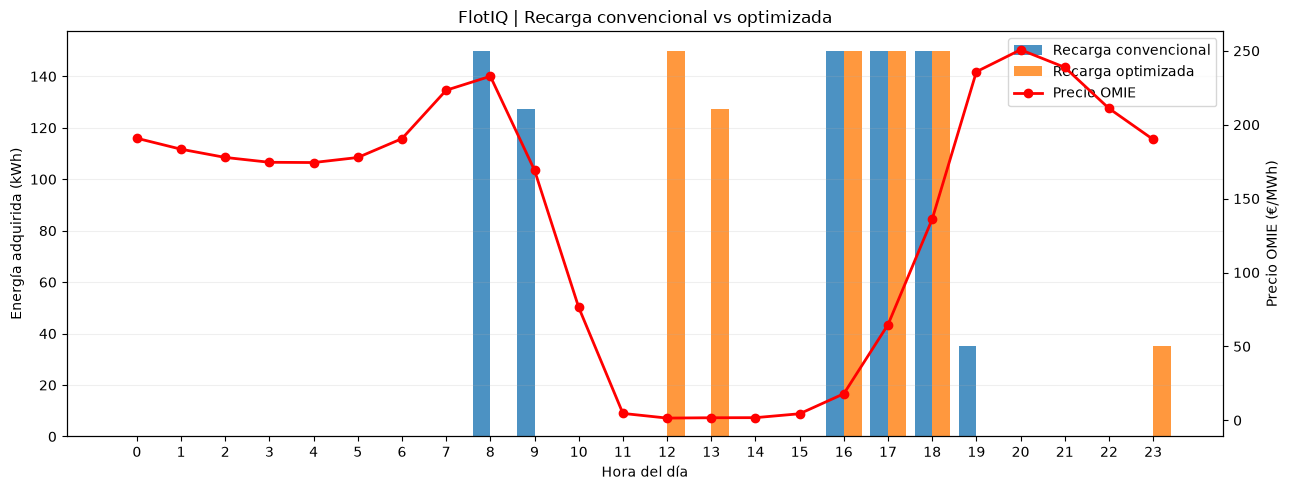

FLOTIQ | COMPARACIÓN HORARIA


,Hora,Convencional_kWh,Optimizada_kWh,Precio_OMIE
2026-09-21 00:00:00,0,0.00,0.00,190.83
2026-09-21 01:00:00,1,0.00,0.00,183.42
2026-09-21 02:00:00,2,0.00,0.00,177.86
2026-09-21 03:00:00,3,0.00,0.00,174.58
2026-09-21 04:00:00,4,0.00,0.00,174.40
2026-09-21 05:00:00,5,0.00,0.00,177.82
2026-09-21 06:00:00,6,0.00,0.00,190.58
2026-09-21 07:00:00,7,0.00,0.00,223.32
2026-09-21 08:00:00,8,150.00,0.00,232.78
2026-09-21 09:00:00,9,127.48,0.00,169.20


In [28]:

# FLOTIQ | COMPARACIÓN HORARIA DE LAS RECARGAS

import matplotlib.pyplot as plt
import pandas as pd

# Recarga convencional por hora
carga_convencional = (
    baseline_dia
    .groupby("hora")["recarga_red_kwh"]
    .sum()
)

# Recuperar la carga optimizada del solver
registros_carga_opt = []

for v in vehiculos_opt:
    for t in horas_opt:
        registros_carga_opt.append({
            "hora": horas_dia[t],
            "recarga_red_kwh": float(
                pulp.value(carga[v, t])
            )
        })

df_carga_opt = pd.DataFrame(registros_carga_opt)

carga_optimizada = (
    df_carga_opt
    .groupby("hora")["recarga_red_kwh"]
    .sum()
)

# Precios horarios
precios_horarios = pd.Series(precios).sort_index()

# Preparar comparación
comparacion_horaria = pd.DataFrame({
    "Convencional_kWh": carga_convencional,
    "Optimizada_kWh": carga_optimizada,
    "Precio_OMIE": precios_horarios
}).sort_index()

comparacion_horaria["Hora"] = (
    comparacion_horaria.index.hour
)

# Dibujar la comparación
fig, ax1 = plt.subplots(figsize=(13, 5))

ax1.bar(
    comparacion_horaria["Hora"] - 0.2,
    comparacion_horaria["Convencional_kWh"],
    width=0.4,
    label="Recarga convencional",
    alpha=0.8
)

ax1.bar(
    comparacion_horaria["Hora"] + 0.2,
    comparacion_horaria["Optimizada_kWh"],
    width=0.4,
    label="Recarga optimizada",
    alpha=0.8
)

ax1.set_xlabel("Hora del día")
ax1.set_ylabel("Energía adquirida (kWh)")
ax1.set_xticks(range(24))
ax1.grid(axis="y", alpha=0.2)

ax2 = ax1.twinx()

ax2.plot(
    comparacion_horaria["Hora"],
    comparacion_horaria["Precio_OMIE"],
    color="red",
    marker="o",
    linewidth=2,
    label="Precio OMIE"
)

ax2.set_ylabel("Precio OMIE (€/MWh)")

ax1.set_title(
    "FlotIQ | Recarga convencional vs optimizada"
)

lineas1, etiquetas1 = ax1.get_legend_handles_labels()
lineas2, etiquetas2 = ax2.get_legend_handles_labels()

ax1.legend(
    lineas1 + lineas2,
    etiquetas1 + etiquetas2,
    loc="upper right"
)

plt.tight_layout()
plt.show()

print("FLOTIQ | COMPARACIÓN HORARIA")

display(
    comparacion_horaria[
        [
            "Hora",
            "Convencional_kWh",
            "Optimizada_kWh",
            "Precio_OMIE"
        ]
    ].round(2)
)


In [29]:

# FLOTIQ | OPTIMIZACIÓN CONTINUA DE 48 HORAS

import pulp
import pandas as pd

HORIZONTE_HORAS = 48

# Seleccionar las primeras 48 horas de la semana
inicio_opt = df_horario["hora"].min()

horas_48h = pd.date_range(
    start=inicio_opt,
    periods=HORIZONTE_HORAS,
    freq="h"
)

datos_48h = df_horario[
    df_horario["hora"].isin(horas_48h)
].copy()

baseline_48h = df_costes_inmediata[
    df_costes_inmediata["hora"].isin(horas_48h)
].copy()

vehiculos_48h = sorted(
    datos_48h["vehicle_id"].unique()
)

periodos_48h = range(HORIZONTE_HORAS)

assert len(vehiculos_48h) == NUM_VEHICULOS
assert len(datos_48h) == NUM_VEHICULOS * HORIZONTE_HORAS
assert len(baseline_48h) == len(datos_48h)

# Diccionarios operativos
datos_idx = datos_48h.set_index(
    ["vehicle_id", "hora"]
)

precios_48h = (
    baseline_48h
    .drop_duplicates("hora")
    .set_index("hora")["price_eur_mwh"]
    .to_dict()
)

final_baseline_48h = (
    baseline_48h
    .sort_values("hora")
    .groupby("vehicle_id")["energia_bateria_kwh"]
    .last()
    .to_dict()
)

# Crear modelo matemático
modelo_48h = pulp.LpProblem(
    "FlotIQ_Optimizacion_48h",
    pulp.LpMinimize
)

indices_48h = [
    (v, t)
    for v in vehiculos_48h
    for t in periodos_48h
]

# Variables compatibles con PuLP 4.1
carga_48h = modelo_48h.add_variable_dicts(
    "carga_red",
    indices_48h,
    lowBound=0
)

conexion_48h = modelo_48h.add_variable_dicts(
    "conexion",
    indices_48h,
    cat="Binary"
)

bateria_48h = modelo_48h.add_variable_dicts(
    "bateria",
    indices_48h,
    lowBound=CAPACIDAD_BATERIA_KWH * SOC_MINIMO,
    upBound=CAPACIDAD_BATERIA_KWH * SOC_OBJETIVO
)

# Minimizar el coste eléctrico
modelo_48h += pulp.lpSum(
    carga_48h[v, t]
    * float(precios_48h[horas_48h[t]])
    / 1000
    for v, t in indices_48h
)

# Restricciones operativas
for v in vehiculos_48h:

    for t in periodos_48h:

        hora = horas_48h[t]
        fila = datos_idx.loc[(v, hora)]

        consumo = float(
            fila["energia_consumida_kwh"]
        )

        disponible = bool(
            fila["disponible_carga"]
        )

        if not disponible:
            modelo_48h += conexion_48h[v, t] == 0

        modelo_48h += (
            carga_48h[v, t]
            <= POTENCIA_CARGADOR_KW
            * INTERVALO_HORAS
            * conexion_48h[v, t]
        )

        energia_anterior = (
            CAPACIDAD_BATERIA_KWH * SOC_INICIAL
            if t == 0
            else bateria_48h[v, t - 1]
        )

        modelo_48h += (
            bateria_48h[v, t]
            == energia_anterior
            - consumo
            + carga_48h[v, t] * EFICIENCIA_CARGA
        )

    # Igualar la batería final al escenario convencional
    modelo_48h += (
        bateria_48h[v, HORIZONTE_HORAS - 1]
        == float(final_baseline_48h[v])
    )

# Restricciones de infraestructura
for t in periodos_48h:

    modelo_48h += (
        pulp.lpSum(
            conexion_48h[v, t]
            for v in vehiculos_48h
        )
        <= NUM_CARGADORES
    )

    modelo_48h += (
        pulp.lpSum(
            carga_48h[v, t]
            for v in vehiculos_48h
        )
        <= POTENCIA_MAX_INSTALACION_KW
        * INTERVALO_HORAS
    )

# Resolver
print("FLOTIQ | OPTIMIZACIÓN DE 48 HORAS")
print("Vehículos:", len(vehiculos_48h))
print("Horas:", HORIZONTE_HORAS)
print("Variables:", len(modelo_48h.variables()))
print("\nResolviendo con CBC...")

solver_48h = pulp.COIN_CMD(
    msg=False,
    timeLimit=180
)

resultado_48h = modelo_48h.solve(solver_48h)

estado_48h = resultado_48h.status_str

print("\nEstado del solver:", estado_48h)

# Mostrar únicamente datos diagnósticos.
# Validaremos la factibilidad en el siguiente paso.
valores_completos = all(
    pulp.value(carga_48h[v, t]) is not None
    and pulp.value(bateria_48h[v, t]) is not None
    and pulp.value(conexion_48h[v, t]) is not None
    for v, t in indices_48h
)

print("Variables con valores completos:", valores_completos)

if valores_completos:

    coste_candidato_48h = sum(
        float(pulp.value(carga_48h[v, t]))
        * float(precios_48h[horas_48h[t]])
        / 1000
        for v, t in indices_48h
    )

    coste_baseline_48h = (
        baseline_48h["coste_eur"].sum()
    )

    print(
        f"Coste convencional: {coste_baseline_48h:.2f} €"
    )

    print(
        f"Coste candidato:    {coste_candidato_48h:.2f} €"
    )

    print(
        "\nPendiente: validar todas las restricciones "
        "antes de calcular el ahorro."
    )

else:
    print(
        "CBC no ha devuelto una solución completa. "
        "No podemos comparar costes todavía."
    )


FLOTIQ | OPTIMIZACIÓN DE 48 HORAS
Vehículos: 50
Horas: 48
Variables: 7200

Resolviendo con CBC...

Estado del solver: GapLimit
Variables con valores completos: True
Coste convencional: 267.61 €
Coste candidato:    94.94 €

Pendiente: validar todas las restricciones antes de calcular el ahorro.


In [30]:

# FLOTIQ | VALIDACIÓN DE LA OPTIMIZACIÓN DE 48 HORAS

import numpy as np
import pandas as pd

TOL = 0.01
errores_48h = []
registros_48h = []

for v in vehiculos_48h:

    energia_anterior = CAPACIDAD_BATERIA_KWH * SOC_INICIAL

    for t in periodos_48h:

        hora = horas_48h[t]
        fila = datos_idx.loc[(v, hora)]

        q = float(pulp.value(carga_48h[v, t]))
        b = float(pulp.value(bateria_48h[v, t]))
        z = float(pulp.value(conexion_48h[v, t]))

        consumo = float(fila["energia_consumida_kwh"])
        disponible = bool(fila["disponible_carga"])

        # Validar energía de carga y conexión
        if q < -TOL:
            errores_48h.append(("Carga negativa", v, t))

        if abs(z - round(z)) > TOL:
            errores_48h.append(("Conexión no binaria", v, t))

        if q > POTENCIA_CARGADOR_KW * INTERVALO_HORAS * z + TOL:
            errores_48h.append(("Exceso cargador", v, t))

        if not disponible and (q > TOL or z > TOL):
            errores_48h.append(("Carga durante turno", v, t))

        # Validar batería
        if b < CAPACIDAD_BATERIA_KWH * SOC_MINIMO - TOL:
            errores_48h.append(("Batería bajo mínimo", v, t))

        if b > CAPACIDAD_BATERIA_KWH * SOC_OBJETIVO + TOL:
            errores_48h.append(("Batería sobre máximo", v, t))

        bateria_esperada = (
            energia_anterior
            - consumo
            + q * EFICIENCIA_CARGA
        )

        if abs(b - bateria_esperada) > TOL:
            errores_48h.append(("Balance incorrecto", v, t))

        registros_48h.append({
            "vehicle_id": v,
            "hora": hora,
            "recarga_red_kwh": q,
            "energia_bateria_kwh": b,
            "soc_pct": b / CAPACIDAD_BATERIA_KWH * 100,
            "conectado": z,
            "precio_eur_mwh": float(precios_48h[hora]),
            "coste_eur": q * float(precios_48h[hora]) / 1000
        })

        energia_anterior = b

    # Comprobar batería final por vehículo
    if abs(
        energia_anterior - final_baseline_48h[v]
    ) > TOL:
        errores_48h.append(("Batería final diferente", v))

df_resultado_48h = pd.DataFrame(registros_48h)

# Validar límites globales por hora
resumen_horario_48h = (
    df_resultado_48h
    .groupby("hora")
    .agg(
        energia_red_kwh=("recarga_red_kwh", "sum"),
        conectados=("conectado", "sum")
    )
)

for hora, fila in resumen_horario_48h.iterrows():

    if fila["energia_red_kwh"] > (
        POTENCIA_MAX_INSTALACION_KW * INTERVALO_HORAS + TOL
    ):
        errores_48h.append(("Exceso potencia total", hora))

    if fila["conectados"] > NUM_CARGADORES + TOL:
        errores_48h.append(("Exceso cargadores", hora))

# Comprobar energía y costes totales
energia_convencional_48h = baseline_48h[
    "recarga_red_kwh"
].sum()

energia_calculada_48h = df_resultado_48h[
    "recarga_red_kwh"
].sum()

coste_convencional_48h = baseline_48h[
    "coste_eur"
].sum()

coste_calculado_48h = df_resultado_48h[
    "coste_eur"
].sum()

if abs(
    energia_convencional_48h - energia_calculada_48h
) > TOL:
    errores_48h.append(("Energía total diferente",))

print("FLOTIQ | VALIDACIÓN DE 48 HORAS")
print("Estado del solver:", estado_48h)
print("Restricciones incumplidas:", len(errores_48h))

print("\nCOMPARACIÓN ENERGÉTICA")
print(f"Convencional: {energia_convencional_48h:.2f} kWh")
print(f"Optimizada:   {energia_calculada_48h:.2f} kWh")

print("\nCOMPARACIÓN ECONÓMICA")
print(f"Convencional: {coste_convencional_48h:.2f} €")
print(f"Candidata:    {coste_calculado_48h:.2f} €")

if not errores_48h:

    ahorro_48h = (
        coste_convencional_48h - coste_calculado_48h
    )

    print("\nSOLUCIÓN FACTIBLE: comprobaciones superadas.")
    print("Optimalidad: NO certificada.")

    print(f"Ahorro simulado: {ahorro_48h:.2f} €")
    print(
        f"Reducción: "
        f"{ahorro_48h / coste_convencional_48h * 100:.2f} %"
    )

else:

    print("\nSOLUCIÓN NO VALIDADA")
    print("Primeros errores:", errores_48h[:10])


FLOTIQ | VALIDACIÓN DE 48 HORAS
Estado del solver: GapLimit
Restricciones incumplidas: 0

COMPARACIÓN ENERGÉTICA
Convencional: 1813.19 kWh
Optimizada:   1813.19 kWh

COMPARACIÓN ECONÓMICA
Convencional: 267.61 €
Candidata:    94.94 €

SOLUCIÓN FACTIBLE: comprobaciones superadas.
Optimalidad: NO certificada.
Ahorro simulado: 172.68 €
Reducción: 64.52 %


In [31]:

# FLOTIQ | PREPARAR PREVISIONES PARA OPTIMIZAR RECARGAS

import pandas as pd
from sklearn.base import clone

# Cargar dataset predictivo
ruta_ml = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "omie_ml_hourly.parquet"
)

df_ml = pd.read_parquet(ruta_ml)

df_ml["datetime_utc"] = pd.to_datetime(
    df_ml["datetime_utc"],
    utc=True
)

# Variables seleccionadas en la Fase 3
FEATURES_OPT = [
    "hour_sin",
    "hour_cos",
    "month_sin",
    "month_cos",
    "day_of_week",
    "is_weekend",
    "price_lag_72h",
    "price_lag_168h",
]

TARGET_OPT = "price_eur_mwh"

# Convertir el inicio de la simulación a UTC
inicio_utc = (
    pd.Timestamp(inicio_opt)
    .tz_localize("Europe/Madrid")
    .tz_convert("UTC")
)

fin_utc = inicio_utc + pd.Timedelta(hours=48)

# Entrenar solo con precios anteriores a la emisión
train_pred = df_ml[
    df_ml["datetime_utc"] < inicio_utc
].copy()

# Horizonte de las próximas 48 horas
futuro_pred = df_ml[
    (df_ml["datetime_utc"] >= inicio_utc)
    & (df_ml["datetime_utc"] < fin_utc)
].copy()

assert len(futuro_pred) == 48
assert len(train_pred) > 0

# Comprobar que las variables necesarias existen
assert not futuro_pred[FEATURES_OPT].isna().any().any()

# Configuración seleccionada en validación
from sklearn.ensemble import HistGradientBoostingRegressor

modelo_pred = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=200,
    max_leaf_nodes=15,
    min_samples_leaf=30,
    l2_regularization=1.0,
    random_state=42
)

modelo_pred.fit(
    train_pred[FEATURES_OPT],
    train_pred[TARGET_OPT]
)

# Emitir predicciones de 48 horas
futuro_pred["pred_ml_eur_mwh"] = (
    modelo_pred.predict(
        futuro_pred[FEATURES_OPT]
    )
)

futuro_pred["pred_baseline_eur_mwh"] = (
    futuro_pred["price_lag_168h"]
)

# Mostrar resultado, sin modificar el optimizador aún
print("FLOTIQ | PREVISIONES PARA RECARGA INTELIGENTE")
print("Inicio:", inicio_utc)
print("Horas previstas:", len(futuro_pred))
print("Horas de entrenamiento:", len(train_pred))

display(
    futuro_pred[
        [
            "datetime_utc",
            "price_eur_mwh",
            "pred_ml_eur_mwh",
            "pred_baseline_eur_mwh"
        ]
    ].head(10).round(2)
)


FLOTIQ | PREVISIONES PARA RECARGA INTELIGENTE
Inicio: 2026-09-20 22:00:00+00:00
Horas previstas: 48
Horas de entrenamiento: 32400


C:\Users\dieve\AppData\Local\Temp\ipykernel_2552\961484687.py:103: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(2)


,datetime_utc,price_eur_mwh,pred_ml_eur_mwh,pred_baseline_eur_mwh
32400,2026-09-20 22:00:00+00:00,190.83,214.84,216.34
32401,2026-09-20 23:00:00+00:00,183.42,209.36,209.23
32402,2026-09-21 00:00:00+00:00,177.86,197.49,203.11
32403,2026-09-21 01:00:00+00:00,174.58,197.49,200.36
32404,2026-09-21 02:00:00+00:00,174.40,194.97,202.66
32405,2026-09-21 03:00:00+00:00,177.82,209.40,207.69
32406,2026-09-21 04:00:00+00:00,190.58,219.80,229.86
32407,2026-09-21 05:00:00+00:00,223.32,223.54,255.02
32408,2026-09-21 06:00:00+00:00,232.78,223.54,264.64
32409,2026-09-21 07:00:00+00:00,169.20,206.21,212.58


In [32]:

# FLOTIQ | OPTIMIZACIÓN DE RECARGAS CON MACHINE LEARNING

import numpy as np
import pandas as pd
import pulp

# Guardar el coste del escenario con información perfecta
coste_perfecto_48h = float(coste_calculado_48h)

# Convertir las fechas previstas a la hora de Madrid
predicciones_opt = futuro_pred.copy()

predicciones_opt["hora"] = (
    predicciones_opt["datetime_utc"]
    .dt.tz_convert("Europe/Madrid")
    .dt.tz_localize(None)
)

# Comprobar la correspondencia de las 48 horas
assert len(predicciones_opt) == 48

assert not predicciones_opt["hora"].duplicated().any()

assert set(predicciones_opt["hora"]) == set(horas_48h)

assert predicciones_opt[
    "pred_ml_eur_mwh"
].notna().all()

# Diccionario de precios previstos por el ML
precios_ml = (
    predicciones_opt
    .set_index("hora")["pred_ml_eur_mwh"]
    .to_dict()
)

# Sustituir el objetivo económico del optimizador
# Sin modificar las restricciones ya construidas
nuevo_objetivo = pulp.lpSum(
    carga_48h[v, t]
    * float(precios_ml[horas_48h[t]])
    / 1000
    for v, t in indices_48h
)

modelo_48h.setObjective(nuevo_objetivo)

print("FLOTIQ | OPTIMIZACIÓN CON MACHINE LEARNING")
print("Modelo predictivo: HistGradientBoosting")
print("Vehículos:", len(vehiculos_48h))
print("Horizonte:", len(horas_48h), "horas")
print("Variables:", len(modelo_48h.variables()))

print("\nResolviendo con precios previstos...")

resultado_ml_48h = modelo_48h.solve(
    pulp.COIN_CMD(
        msg=False,
        timeLimit=180
    )
)

estado_ml_48h = resultado_ml_48h.status_str

print("\nEstado del solver:", estado_ml_48h)

# Comprobar si se han recuperado valores
valores_ml_completos = all(
    pulp.value(carga_48h[v, t]) is not None
    and pulp.value(bateria_48h[v, t]) is not None
    and pulp.value(conexion_48h[v, t]) is not None
    for v, t in indices_48h
)

print(
    "Variables con valores completos:",
    valores_ml_completos
)

if valores_ml_completos:

    # Coste real de las decisiones tomadas con ML
    coste_real_ml = sum(
        float(pulp.value(carga_48h[v, t]))
        * float(precios_48h[horas_48h[t]])
        / 1000
        for v, t in indices_48h
    )

    # Coste previsto en el momento de decidir
    coste_previsto_ml = sum(
        float(pulp.value(carga_48h[v, t]))
        * float(precios_ml[horas_48h[t]])
        / 1000
        for v, t in indices_48h
    )

    print("\nCOSTES PROVISIONALES")

    print(
        f"Convencional:        "
        f"{coste_baseline_48h:.2f} €"
    )

    print(
        f"Información perfecta: "
        f"{coste_perfecto_48h:.2f} €"
    )

    print(
        f"Decisiones con ML:   "
        f"{coste_real_ml:.2f} €"
    )

    print(
        f"Coste previsto ML:   "
        f"{coste_previsto_ml:.2f} €"
    )

    print(
        "\nPendiente: validar la factibilidad "
        "de la nueva solución."
    )

else:
    print(
        "\nNo tenemos una solución completa. "
        "No se pueden comparar costes."
    )


FLOTIQ | OPTIMIZACIÓN CON MACHINE LEARNING
Modelo predictivo: HistGradientBoosting
Vehículos: 50
Horizonte: 48 horas
Variables: 7200

Resolviendo con precios previstos...

Estado del solver: GapLimit
Variables con valores completos: True

COSTES PROVISIONALES
Convencional:        267.61 €
Información perfecta: 94.94 €
Decisiones con ML:   99.54 €
Coste previsto ML:   109.86 €

Pendiente: validar la factibilidad de la nueva solución.


In [33]:

# FLOTIQ | VALIDAR OPTIMIZACIÓN CON MACHINE LEARNING

import pandas as pd
import pulp

TOL = 0.01
errores_ml = []
registros_ml = []

assert valores_ml_completos, (
    "El solver no devolvió valores completos"
)

for v in vehiculos_48h:

    energia_anterior = (
        CAPACIDAD_BATERIA_KWH * SOC_INICIAL
    )

    for t in periodos_48h:

        hora = horas_48h[t]
        fila = datos_idx.loc[(v, hora)]

        q = float(pulp.value(carga_48h[v, t]))
        b = float(pulp.value(bateria_48h[v, t]))
        z = float(pulp.value(conexion_48h[v, t]))

        consumo = float(
            fila["energia_consumida_kwh"]
        )

        disponible = bool(
            fila["disponible_carga"]
        )

        # Validar cargadores y disponibilidad
        if q < -TOL:
            errores_ml.append(("Carga negativa", v, t))

        if abs(z - round(z)) > TOL:
            errores_ml.append(("Conexión no binaria", v, t))

        if z < -TOL or z > 1 + TOL:
            errores_ml.append(("Conexión fuera de rango", v, t))

        if q > (
            POTENCIA_CARGADOR_KW
            * INTERVALO_HORAS
            * z
            + TOL
        ):
            errores_ml.append(("Exceso cargador", v, t))

        if not disponible and (q > TOL or z > TOL):
            errores_ml.append(("Carga durante turno", v, t))

        # Validar estado de batería
        if b < (
            CAPACIDAD_BATERIA_KWH * SOC_MINIMO - TOL
        ):
            errores_ml.append(("SOC bajo mínimo", v, t))

        if b > (
            CAPACIDAD_BATERIA_KWH * SOC_OBJETIVO + TOL
        ):
            errores_ml.append(("SOC sobre máximo", v, t))

        bateria_esperada = (
            energia_anterior
            - consumo
            + q * EFICIENCIA_CARGA
        )

        if abs(b - bateria_esperada) > TOL:
            errores_ml.append(("Balance incorrecto", v, t))

        registros_ml.append({
            "vehicle_id": v,
            "hora": hora,
            "recarga_red_kwh": q,
            "energia_bateria_kwh": b,
            "soc_pct": b / CAPACIDAD_BATERIA_KWH * 100,
            "conectado": z,
            "precio_real_eur_mwh": float(
                precios_48h[hora]
            ),
            "precio_previsto_eur_mwh": float(
                precios_ml[hora]
            )
        })

        energia_anterior = b

    # Mismo estado final que la recarga convencional
    if abs(
        energia_anterior - final_baseline_48h[v]
    ) > TOL:
        errores_ml.append(("Batería final diferente", v))

df_resultado_ml_48h = pd.DataFrame(registros_ml)

# Validar potencia y cargadores por hora
uso_ml = (
    df_resultado_ml_48h
    .groupby("hora")
    .agg(
        energia_red_kwh=("recarga_red_kwh", "sum"),
        coches_conectados=("conectado", "sum")
    )
)

for hora, fila in uso_ml.iterrows():

    if fila["energia_red_kwh"] > (
        POTENCIA_MAX_INSTALACION_KW
        * INTERVALO_HORAS
        + TOL
    ):
        errores_ml.append(("Exceso potencia", hora))

    if fila["coches_conectados"] > NUM_CARGADORES + TOL:
        errores_ml.append(("Exceso cargadores", hora))

# Calcular energía y coste realmente obtenidos
df_resultado_ml_48h["coste_real_eur"] = (
    df_resultado_ml_48h["recarga_red_kwh"]
    * df_resultado_ml_48h["precio_real_eur_mwh"]
    / 1000
)

energia_ml = df_resultado_ml_48h[
    "recarga_red_kwh"
].sum()

energia_convencional = baseline_48h[
    "recarga_red_kwh"
].sum()

coste_ml_validacion = df_resultado_ml_48h[
    "coste_real_eur"
].sum()

coste_convencional = baseline_48h[
    "coste_eur"
].sum()

if abs(energia_ml - energia_convencional) > TOL:
    errores_ml.append(("Energía total diferente",))

print("FLOTIQ | VALIDACIÓN DE RECARGA INTELIGENTE")

print("Estado solver:", estado_ml_48h)
print("Restricciones incumplidas:", len(errores_ml))

print("\nENERGÍA ADQUIRIDA")
print(f"Convencional: {energia_convencional:.2f} kWh")
print(f"Machine Learning: {energia_ml:.2f} kWh")

print("\nCOSTES REALES OMIE")
print(f"Convencional: {coste_convencional:.2f} €")
print(f"Machine Learning: {coste_ml_validacion:.2f} €")

if len(errores_ml) == 0:

    ahorro_ml_validado = (
        coste_convencional - coste_ml_validacion
    )

    ahorro_ml_pct = (
        ahorro_ml_validado
        / coste_convencional
        * 100
    )

    print("\nSOLUCIÓN FACTIBLE")
    print("Optimalidad: no certificada")

    print(f"Reducción: {ahorro_ml_validado:.2f} €")
    print(f"Porcentaje: {ahorro_ml_pct:.2f} %")

    print(
        "SOC mínimo:",
        round(df_resultado_ml_48h["soc_pct"].min(), 2),
        "%"
    )

    print(
        "Potencia máxima:",
        round(
            uso_ml["energia_red_kwh"].max()
            / INTERVALO_HORAS, 2
        ),
        "kW"
    )

else:
    print("\nSOLUCIÓN NO VALIDADA")
    print("Primeros errores:", errores_ml[:10])


FLOTIQ | VALIDACIÓN DE RECARGA INTELIGENTE
Estado solver: GapLimit
Restricciones incumplidas: 0

ENERGÍA ADQUIRIDA
Convencional: 1813.19 kWh
Machine Learning: 1813.19 kWh

COSTES REALES OMIE
Convencional: 267.61 €
Machine Learning: 99.54 €

SOLUCIÓN FACTIBLE
Optimalidad: no certificada
Reducción: 168.07 €
Porcentaje: 62.80 %
SOC mínimo: 20.23 %
Potencia máxima: 150.0 kW


In [37]:

# FLOTIQ | OPTIMIZACIÓN CON BASELINE SEMANAL

import pulp
import pandas as pd
import numpy as np

# Guardar resultados ya validados
coste_ml_referencia = float(coste_ml_validacion)
coste_perfecto_referencia = float(coste_perfecto_48h)
coste_convencional_referencia = float(
    baseline_48h["coste_eur"].sum()
)

# Precios previstos por el baseline semanal
precios_baseline_pred = (
    predicciones_opt
    .set_index("hora")["pred_baseline_eur_mwh"]
    .to_dict()
)

assert set(precios_baseline_pred) == set(horas_48h)

assert all(
    np.isfinite(float(precios_baseline_pred[h]))
    for h in horas_48h
)

# Crear un modelo independiente
modelo_baseline_48h = pulp.LpProblem(
    "FlotIQ_Baseline_Semanal_48h",
    pulp.LpMinimize
)

# Variables compatibles con PuLP 4.1
carga_bl = modelo_baseline_48h.add_variable_dicts(
    "carga_red",
    indices_48h,
    lowBound=0
)

conexion_bl = modelo_baseline_48h.add_variable_dicts(
    "conexion",
    indices_48h,
    cat="Binary"
)

bateria_bl = modelo_baseline_48h.add_variable_dicts(
    "bateria",
    indices_48h,
    lowBound=CAPACIDAD_BATERIA_KWH * SOC_MINIMO,
    upBound=CAPACIDAD_BATERIA_KWH * SOC_OBJETIVO
)

# Objetivo: minimizar el coste previsto
modelo_baseline_48h += pulp.lpSum(
    carga_bl[v, t]
    * float(precios_baseline_pred[horas_48h[t]])
    / 1000
    for v, t in indices_48h
)

# Restricciones por vehículo
for v in vehiculos_48h:

    for t in periodos_48h:

        hora = horas_48h[t]
        fila = datos_idx.loc[(v, hora)]

        consumo = float(
            fila["energia_consumida_kwh"]
        )

        disponible = bool(
            fila["disponible_carga"]
        )

        # Prohibir recargas durante los turnos
        if not disponible:
            modelo_baseline_48h += (
                conexion_bl[v, t] == 0
            )

        # Máxima energía por cargador
        modelo_baseline_48h += (
            carga_bl[v, t]
            <= POTENCIA_CARGADOR_KW
            * INTERVALO_HORAS
            * conexion_bl[v, t]
        )

        # Estado anterior de batería
        if t == 0:
            energia_anterior = (
                CAPACIDAD_BATERIA_KWH
                * SOC_INICIAL
            )
        else:
            energia_anterior = bateria_bl[v, t - 1]

        # Balance energético
        modelo_baseline_48h += (
            bateria_bl[v, t]
            == energia_anterior
            - consumo
            + carga_bl[v, t] * EFICIENCIA_CARGA
        )

    # Mismo SOC final que la recarga convencional
    modelo_baseline_48h += (
        bateria_bl[v, HORIZONTE_HORAS - 1]
        == float(final_baseline_48h[v])
    )

# Restricciones de la instalación
for t in periodos_48h:

    # Máximo 20 cargadores
    modelo_baseline_48h += (
        pulp.lpSum(
            conexion_bl[v, t]
            for v in vehiculos_48h
        )
        <= NUM_CARGADORES
    )

    # Máximo 150 kW de potencia
    modelo_baseline_48h += (
        pulp.lpSum(
            carga_bl[v, t]
            for v in vehiculos_48h
        )
        <= POTENCIA_MAX_INSTALACION_KW
        * INTERVALO_HORAS
    )

print("FLOTIQ | OPTIMIZACIÓN CON BASELINE SEMANAL")
print("Vehículos:", len(vehiculos_48h))
print("Horas:", HORIZONTE_HORAS)
print("Variables:", len(modelo_baseline_48h.variables()))
print("Restricciones:", len(modelo_baseline_48h.constraints()))

# Resolver utilizando CBC
print("\nResolviendo con CBC...")

solver_bl = pulp.COIN_CMD(
    msg=False,
    timeLimit=180
)

try:
    resultado_baseline_pred = (
        modelo_baseline_48h.solve(solver_bl)
    )

except pulp.PulpSolverError as error:
    print("\nERROR AL EJECUTAR CBC")
    print(str(error))
    print(
        "El modelo independiente también ha fallado. "
        "Habrá que revisar el diagnóstico del ejecutable."
    )
    raise

estado_baseline_pred = (
    resultado_baseline_pred.status_str
)

print("\nEstado del solver:", estado_baseline_pred)

# Comprobar que CBC devolvió valores
valores_completos = all(
    pulp.value(carga_bl[v, t]) is not None
    and pulp.value(bateria_bl[v, t]) is not None
    and pulp.value(conexion_bl[v, t]) is not None
    for v, t in indices_48h
)

print("Variables con valores completos:", valores_completos)

if not valores_completos:
    raise ValueError(
        "CBC no ha devuelto una solución completa"
    )

# Validar la solución candidata
TOL = 0.01

errores_baseline_pred = []
registros_baseline_pred = []

for v in vehiculos_48h:

    energia_anterior = (
        CAPACIDAD_BATERIA_KWH * SOC_INICIAL
    )

    for t in periodos_48h:

        hora = horas_48h[t]
        fila = datos_idx.loc[(v, hora)]

        q = float(pulp.value(carga_bl[v, t]))
        b = float(pulp.value(bateria_bl[v, t]))
        z = float(pulp.value(conexion_bl[v, t]))

        consumo = float(
            fila["energia_consumida_kwh"]
        )

        disponible = bool(
            fila["disponible_carga"]
        )

        # Valores numéricos válidos
        if not all(np.isfinite(x) for x in [q, b, z]):
            errores_baseline_pred.append(
                ("Valor no finito", v, t)
            )
            continue

        # Energía no negativa
        if q < -TOL:
            errores_baseline_pred.append(
                ("Carga negativa", v, t)
            )

        # Conexión binaria
        if abs(z - round(z)) > TOL:
            errores_baseline_pred.append(
                ("Conexión no binaria", v, t)
            )

        if z < -TOL or z > 1 + TOL:
            errores_baseline_pred.append(
                ("Conexión fuera de rango", v, t)
            )

        # Límite individual del cargador
        if q > (
            POTENCIA_CARGADOR_KW
            * INTERVALO_HORAS
            * z
            + TOL
        ):
            errores_baseline_pred.append(
                ("Exceso cargador", v, t)
            )

        # Disponibilidad del vehículo
        if not disponible and (q > TOL or z > TOL):
            errores_baseline_pred.append(
                ("Carga durante turno", v, t)
            )

        # Límites de batería
        if b < (
            CAPACIDAD_BATERIA_KWH * SOC_MINIMO - TOL
        ):
            errores_baseline_pred.append(
                ("SOC bajo mínimo", v, t)
            )

        if b > (
            CAPACIDAD_BATERIA_KWH * SOC_OBJETIVO + TOL
        ):
            errores_baseline_pred.append(
                ("SOC sobre máximo", v, t)
            )

        # Conservación de energía
        bateria_esperada = (
            energia_anterior
            - consumo
            + q * EFICIENCIA_CARGA
        )

        if abs(b - bateria_esperada) > TOL:
            errores_baseline_pred.append(
                ("Balance incorrecto", v, t)
            )

        registros_baseline_pred.append({
            "vehicle_id": v,
            "hora": hora,
            "recarga_red_kwh": q,
            "energia_bateria_kwh": b,
            "soc_pct": (
                b / CAPACIDAD_BATERIA_KWH * 100
            ),
            "conectado": z,
            "precio_real_eur_mwh": float(
                precios_48h[hora]
            ),
            "precio_previsto_eur_mwh": float(
                precios_baseline_pred[hora]
            ),
            "coste_real_eur": (
                q * float(precios_48h[hora]) / 1000
            )
        })

        energia_anterior = b

    # Verificar batería final de cada Tesla
    if abs(
        energia_anterior - final_baseline_48h[v]
    ) > TOL:
        errores_baseline_pred.append(
            ("Batería final diferente", v)
        )

# Crear tabla de resultados
df_baseline_pred_48h = pd.DataFrame(
    registros_baseline_pred
)

# Comprobar límites de la instalación
uso_baseline_pred = (
    df_baseline_pred_48h
    .groupby("hora")
    .agg(
        energia_red_kwh=("recarga_red_kwh", "sum"),
        conexiones=("conectado", "sum")
    )
)

for hora, fila in uso_baseline_pred.iterrows():

    if fila["energia_red_kwh"] > (
        POTENCIA_MAX_INSTALACION_KW
        * INTERVALO_HORAS
        + TOL
    ):
        errores_baseline_pred.append(
            ("Exceso potencia total", hora)
        )

    if fila["conexiones"] > NUM_CARGADORES + TOL:
        errores_baseline_pred.append(
            ("Exceso cargadores", hora)
        )

# Comprobar energía total
energia_baseline_pred = (
    df_baseline_pred_48h["recarga_red_kwh"].sum()
)

energia_referencia = (
    baseline_48h["recarga_red_kwh"].sum()
)

if abs(
    energia_baseline_pred - energia_referencia
) > TOL:
    errores_baseline_pred.append(
        ("Energía total diferente",)
    )

# Mostrar resultado
print("\nFLOTIQ | VALIDACIÓN DEL BASELINE")
print("Restricciones incumplidas:", len(errores_baseline_pred))

if errores_baseline_pred:

    print("\nSOLUCIÓN NO VALIDADA")
    print("Primeros errores:", errores_baseline_pred[:10])
    print("No se calcularán ahorros.")

else:

    coste_baseline_pred_real = (
        df_baseline_pred_48h["coste_real_eur"].sum()
    )

    diferencia_ml = (
        coste_baseline_pred_real
        - coste_ml_referencia
    )

    print("\nSOLUCIÓN FACTIBLE")
    print(
        "Optimalidad certificada:",
        estado_baseline_pred == "Optimal"
    )

    print("\nCOMPARACIÓN DE ESTRATEGIAS (48 HORAS)")

    print(
        f"Recarga inmediata:       "
        f"{coste_convencional_referencia:.2f} €"
    )

    print(
        f"Optimización baseline:   "
        f"{coste_baseline_pred_real:.2f} €"
    )

    print(
        f"Optimización ML:         "
        f"{coste_ml_referencia:.2f} €"
    )

    print(
        f"Información perfecta:    "
        f"{coste_perfecto_referencia:.2f} €"
    )

    print("\nDIFERENCIA ML VS BASELINE")

    print(
        f"Diferencia de costes: "
        f"{diferencia_ml:.2f} €"
    )

    if diferencia_ml > 0:
        print(
            "En esta simulación, ML ha resultado "
            "más económico que el baseline."
        )

    elif diferencia_ml < 0:
        print(
            "En esta simulación, el baseline ha "
            "resultado más económico que ML."
        )

    else:
        print(
            "Ambas estrategias tienen el mismo coste."
        )

    print("\nCOMPROBACIONES")
    print(
        f"Energía adquirida: "
        f"{energia_baseline_pred:.2f} kWh"
    )

    print(
        f"SOC mínimo: "
        f"{df_baseline_pred_48h['soc_pct'].min():.2f} %"
    )

    print(
        f"Potencia máxima: "
        f"{uso_baseline_pred['energia_red_kwh'].max() / INTERVALO_HORAS:.2f} kW"
    )

    print("Restricciones operativas: OK")


FLOTIQ | OPTIMIZACIÓN CON BASELINE SEMANAL
Vehículos: 50
Horas: 48
Variables: 7200
Restricciones: 5850

Resolviendo con CBC...

Estado del solver: GapLimit
Variables con valores completos: True

FLOTIQ | VALIDACIÓN DEL BASELINE
Restricciones incumplidas: 0

SOLUCIÓN FACTIBLE
Optimalidad certificada: False

COMPARACIÓN DE ESTRATEGIAS (48 HORAS)
Recarga inmediata:       267.61 €
Optimización baseline:   97.00 €
Optimización ML:         99.54 €
Información perfecta:    94.94 €

DIFERENCIA ML VS BASELINE
Diferencia de costes: -2.54 €
En esta simulación, el baseline ha resultado más económico que ML.

COMPROBACIONES
Energía adquirida: 1813.19 kWh
SOC mínimo: 20.23 %
Potencia máxima: 150.00 kW
Restricciones operativas: OK


In [38]:

# FLOTIQ | GUARDAR COMPARACIÓN DE ESTRATEGIAS

from pathlib import Path
import pandas as pd

carpeta_resultados = (
    PROJECT_ROOT / "data" / "processed"
)

carpeta_resultados.mkdir(
    parents=True,
    exist_ok=True
)

comparacion_estrategias_48h = pd.DataFrame([
    {
        "estrategia": "Recarga inmediata",
        "coste_eur": coste_convencional_referencia,
        "energia_red_kwh": energia_referencia
    },
    {
        "estrategia": "Baseline semanal optimizado",
        "coste_eur": coste_baseline_pred_real,
        "energia_red_kwh": energia_baseline_pred
    },
    {
        "estrategia": "HistGradientBoosting optimizado",
        "coste_eur": coste_ml_referencia,
        "energia_red_kwh": energia_ml
    },
    {
        "estrategia": "Información perfecta",
        "coste_eur": coste_perfecto_referencia,
        "energia_red_kwh": energia_calculada_48h
    }
])

comparacion_estrategias_48h["ahorro_pct"] = (
    (
        coste_convencional_referencia
        - comparacion_estrategias_48h["coste_eur"]
    )
    / coste_convencional_referencia
    * 100
)

ruta_resumen = (
    carpeta_resultados
    / "comparacion_recargas_48h.csv"
)

comparacion_estrategias_48h.to_csv(
    ruta_resumen,
    index=False
)

# Guardar también la planificación horaria
df_resultado_ml_48h.to_parquet(
    carpeta_resultados / "recargas_ml_48h.parquet",
    index=False
)

df_baseline_pred_48h.to_parquet(
    carpeta_resultados / "recargas_baseline_48h.parquet",
    index=False
)

print("FLOTIQ | RESULTADOS GUARDADOS")
display(comparacion_estrategias_48h.round(2))
print("\nArchivos guardados en:", carpeta_resultados)


FLOTIQ | RESULTADOS GUARDADOS


,estrategia,coste_eur,energia_red_kwh,ahorro_pct
0,Recarga inmediata,267.61,1813.19,0.00
1,Baseline semanal optimizado,97.00,1813.19,63.75
2,HistGradientBoosting optimizado,99.54,1813.19,62.80
3,Información perfecta,94.94,1813.19,64.52



Archivos guardados en: c:\Users\dieve\OneDrive\Escritorio\Bootcamp\FlotIQ\data\processed


In [39]:

# FLOTIQ | CALENDARIO DE OPTIMIZACIÓN SEMANAL

import pandas as pd

inicio_semana = df_horario["hora"].min()
fin_semana = df_horario["hora"].max() + pd.Timedelta(hours=1)

calendario = []

for inicio in pd.date_range(
    start=inicio_semana,
    end=fin_semana,
    freq="24h",
    inclusive="left"
):
    fin_prediccion = min(
        inicio + pd.Timedelta(hours=48),
        fin_semana
    )

    fin_ejecucion = min(
        inicio + pd.Timedelta(hours=24),
        fin_semana
    )

    calendario.append({
        "Dia": len(calendario) + 1,
        "Inicio": inicio,
        "Fin_prevision": fin_prediccion,
        "Horas_prevision": int(
            (fin_prediccion - inicio)
            / pd.Timedelta(hours=1)
        ),
        "Horas_ejecutadas": int(
            (fin_ejecucion - inicio)
            / pd.Timedelta(hours=1)
        )
    })

df_calendario = pd.DataFrame(calendario)

assert df_calendario["Horas_ejecutadas"].sum() == 168
assert len(df_calendario) == 7

print("FLOTIQ | PLANIFICACIÓN SEMANAL")
print("Días:", len(df_calendario))
print(
    "Horas totales:",
    df_calendario["Horas_ejecutadas"].sum()
)

display(df_calendario)


FLOTIQ | PLANIFICACIÓN SEMANAL
Días: 7
Horas totales: 168


,Dia,Inicio,Fin_prevision,Horas_prevision,Horas_ejecutadas
0,1,2026-09-21,2026-09-23,48,24
1,2,2026-09-22,2026-09-24,48,24
2,3,2026-09-23,2026-09-25,48,24
3,4,2026-09-24,2026-09-26,48,24
4,5,2026-09-25,2026-09-27,48,24
5,6,2026-09-26,2026-09-28,48,24
6,7,2026-09-27,2026-09-28,24,24


In [40]:

# FLOTIQ | PREVISIONES DIARIAS PARA LA SEMANA

import pandas as pd
import numpy as np
from sklearn.ensemble import HistGradientBoostingRegressor

# Utilizamos el dataset ML ya cargado anteriormente
df_ml = df_ml.sort_values(
    "datetime_utc"
).copy()

resultados_previsiones = []
resumen_previsiones = []

for fila in df_calendario.itertuples(index=False):

    dia = fila.Dia

    # Convertir el inicio de cada día a UTC
    inicio_utc = (
        pd.Timestamp(fila.Inicio)
        .tz_localize("Europe/Madrid")
        .tz_convert("UTC")
    )

    fin_utc = inicio_utc + pd.Timedelta(
        hours=fila.Horas_prevision
    )

    # Solo datos anteriores a la emisión
    datos_train = df_ml[
        df_ml["datetime_utc"] < inicio_utc
    ].copy()

    # Horas que queremos predecir
    datos_futuro = df_ml[
        (df_ml["datetime_utc"] >= inicio_utc)
        & (df_ml["datetime_utc"] < fin_utc)
    ].copy()

    assert len(datos_futuro) == fila.Horas_prevision
    assert len(datos_train) > 0

    assert datos_train["datetime_utc"].max() < inicio_utc

    assert not datos_futuro[FEATURES_OPT].isna().any().any()

    # Crear y entrenar el modelo de ese día
    modelo_diario = HistGradientBoostingRegressor(
        learning_rate=0.05,
        max_iter=200,
        max_leaf_nodes=15,
        min_samples_leaf=30,
        l2_regularization=1.0,
        random_state=42
    )

    modelo_diario.fit(
        datos_train[FEATURES_OPT],
        datos_train[TARGET_OPT]
    )

    # Predecir las próximas horas
    datos_futuro["precio_ml"] = modelo_diario.predict(
        datos_futuro[FEATURES_OPT]
    )

    datos_futuro["precio_baseline"] = (
        datos_futuro["price_lag_168h"]
    )

    datos_futuro["dia_planificacion"] = dia

    # Convertir a hora local para el optimizador
    datos_futuro["hora"] = (
        datos_futuro["datetime_utc"]
        .dt.tz_convert("Europe/Madrid")
        .dt.tz_localize(None)
    )

    resultados_previsiones.append(
        datos_futuro[
            [
                "dia_planificacion",
                "hora",
                "datetime_utc",
                "price_eur_mwh",
                "precio_ml",
                "precio_baseline"
            ]
        ]
    )

    # Resumir cada ventana
    error_ml = np.mean(
        np.abs(
            datos_futuro["price_eur_mwh"]
            - datos_futuro["precio_ml"]
        )
    )

    error_baseline = np.mean(
        np.abs(
            datos_futuro["price_eur_mwh"]
            - datos_futuro["precio_baseline"]
        )
    )

    resumen_previsiones.append({
        "Dia": dia,
        "Horas previstas": len(datos_futuro),
        "Filas entrenamiento": len(datos_train),
        "MAE ML": round(error_ml, 2),
        "MAE Baseline": round(error_baseline, 2)
    })

# Unir todas las previsiones
df_previsiones_semana = pd.concat(
    resultados_previsiones,
    ignore_index=True
)

df_resumen_previsiones = pd.DataFrame(
    resumen_previsiones
)

assert len(df_resumen_previsiones) == 7

assert len(df_previsiones_semana) == 312

print("FLOTIQ | PREVISIONES SEMANALES")
print("Días de planificación:", len(df_resumen_previsiones))
print("Predicciones generadas:", len(df_previsiones_semana))

print("\nRESULTADOS POR DÍA")
display(df_resumen_previsiones)

print("\nPRIMERAS 10 PREDICCIONES")
display(
    df_previsiones_semana[
        [
            "dia_planificacion",
            "hora",
            "price_eur_mwh",
            "precio_ml",
            "precio_baseline"
        ]
    ].head(10).round({
        "price_eur_mwh": 2,
        "precio_ml": 2,
        "precio_baseline": 2
    })
)


FLOTIQ | PREVISIONES SEMANALES
Días de planificación: 7
Predicciones generadas: 312

RESULTADOS POR DÍA


,Dia,Horas previstas,Filas entrenamiento,MAE ML,MAE Baseline
0,1,48,32400,21.95,33.28
1,2,48,32424,31.34,41.07
2,3,48,32448,31.74,43.02
3,4,48,32472,23.68,32.97
4,5,48,32496,15.41,27.28
5,6,48,32520,13.40,18.88
6,7,24,32544,16.58,17.34



PRIMERAS 10 PREDICCIONES


,dia_planificacion,hora,price_eur_mwh,precio_ml,precio_baseline
0,1,2026-09-21 00:00:00,190.83,214.84,216.34
1,1,2026-09-21 01:00:00,183.42,209.36,209.23
2,1,2026-09-21 02:00:00,177.86,197.49,203.11
3,1,2026-09-21 03:00:00,174.58,197.49,200.36
4,1,2026-09-21 04:00:00,174.40,194.97,202.66
5,1,2026-09-21 05:00:00,177.82,209.40,207.69
6,1,2026-09-21 06:00:00,190.58,219.80,229.86
7,1,2026-09-21 07:00:00,223.32,223.54,255.02
8,1,2026-09-21 08:00:00,232.78,223.54,264.64
9,1,2026-09-21 09:00:00,169.20,206.21,212.58


In [41]:

# FLOTIQ | EJECUTAR PRIMER DÍA DEL HORIZONTE MÓVIL

import pandas as pd
import numpy as np

# Seleccionar el primer día del calendario semanal
primer_ciclo = df_calendario.iloc[0]

inicio_dia = pd.Timestamp(primer_ciclo["Inicio"])

fin_dia = inicio_dia + pd.Timedelta(hours=24)

# Recuperar la planificación ML validada de 48 horas
df_ejecucion_dia1 = df_resultado_ml_48h[
    (df_resultado_ml_48h["hora"] >= inicio_dia)
    & (df_resultado_ml_48h["hora"] < fin_dia)
].copy()

# Comprobar que tenemos 24 horas de los 50 Tesla
assert len(df_ejecucion_dia1) == 50 * 24

assert (
    df_ejecucion_dia1["vehicle_id"].nunique() == 50
)

assert (
    df_ejecucion_dia1["hora"].nunique() == 24
)

assert not df_ejecucion_dia1[
    ["vehicle_id", "hora"]
].duplicated().any()

# Obtener la batería final del primer día
estado_baterias_dia1 = (
    df_ejecucion_dia1
    .sort_values(["vehicle_id", "hora"])
    .groupby("vehicle_id")["energia_bateria_kwh"]
    .last()
    .to_dict()
)

assert len(estado_baterias_dia1) == 50

# Comprobar límites de batería
energia_minima = CAPACIDAD_BATERIA_KWH * SOC_MINIMO
energia_maxima = CAPACIDAD_BATERIA_KWH * SOC_OBJETIVO

assert all(
    energia_minima - 0.01 <= energia <= energia_maxima + 0.01
    for energia in estado_baterias_dia1.values()
)

# Calcular coste del primer día ejecutado
coste_dia1_ml = (
    df_ejecucion_dia1["coste_real_eur"].sum()
)

energia_dia1_ml = (
    df_ejecucion_dia1["recarga_red_kwh"].sum()
)

soc_finales = np.array(
    list(estado_baterias_dia1.values())
) / CAPACIDAD_BATERIA_KWH * 100

# Comparación descriptiva con recarga inmediata
baseline_dia1 = df_costes_inmediata[
    (df_costes_inmediata["hora"] >= inicio_dia)
    & (df_costes_inmediata["hora"] < fin_dia)
].copy()

coste_dia1_inmediata = baseline_dia1[
    "coste_eur"
].sum()

# Guardar solo las 24 horas realmente ejecutadas
df_recargas_ejecutadas = (
    df_ejecucion_dia1.copy()
)

# Estado inicial del siguiente ciclo
estado_baterias_actual = (
    estado_baterias_dia1.copy()
)

print("FLOTIQ | HORIZONTE MÓVIL — DÍA 1")
print("Inicio:", inicio_dia)
print("Fin:", fin_dia)

print("\nOPERACIÓN")
print("Vehículos:", len(estado_baterias_actual))
print("Horas ejecutadas:", 24)

print(
    "Energía adquirida:",
    round(energia_dia1_ml, 2),
    "kWh"
)

print(
    "Coste real ML:",
    round(coste_dia1_ml, 2),
    "€"
)

print(
    "Coste recarga inmediata:",
    round(coste_dia1_inmediata, 2),
    "€"
)

print("\nESTADO DE LAS BATERÍAS")
print("SOC mínimo final:", round(soc_finales.min(), 2), "%")
print("SOC medio final:", round(soc_finales.mean(), 2), "%")
print("SOC máximo final:", round(soc_finales.max(), 2), "%")

print("\nPRIMEROS 10 VEHÍCULOS")

display(
    pd.DataFrame({
        "vehicle_id": list(estado_baterias_actual.keys()),
        "energia_final_kwh": list(estado_baterias_actual.values())
    }).head(10).round(2)
)

print("\nEstado listo para planificar el día 2.")


FLOTIQ | HORIZONTE MÓVIL — DÍA 1
Inicio: 2026-09-21 00:00:00
Fin: 2026-09-22 00:00:00

OPERACIÓN
Vehículos: 50
Horas ejecutadas: 24
Energía adquirida: 630.14 kWh
Coste real ML: 20.06 €
Coste recarga inmediata: 97.61 €

ESTADO DE LAS BATERÍAS
SOC mínimo final: 49.26 %
SOC medio final: 65.85 %
SOC máximo final: 80.0 %

PRIMEROS 10 VEHÍCULOS


,vehicle_id,energia_final_kwh
0,V001,31.41
1,V002,31.20
2,V003,29.99
3,V004,33.40
4,V005,31.34
5,V006,30.33
6,V007,30.62
7,V008,48.00
8,V009,48.00
9,V010,48.00



Estado listo para planificar el día 2.


In [42]:

# FLOTIQ | HORIZONTE MÓVIL - PLANIFICACIÓN DEL DÍA 2

import pandas as pd
import numpy as np
import pulp

# Segundo ciclo del calendario
ciclo = df_calendario.iloc[1]

inicio_dia2 = pd.Timestamp(ciclo["Inicio"])
horas_dia2 = pd.date_range(
    start=inicio_dia2,
    periods=int(ciclo["Horas_prevision"]),
    freq="h"
)

T = list(range(len(horas_dia2)))
V = sorted(estado_baterias_actual.keys())
indices_dia2 = [(v, t) for v in V for t in T]

# Datos operativos del horizonte
operaciones = df_horario[
    df_horario["hora"].isin(horas_dia2)
].set_index(["vehicle_id", "hora"])

assert len(operaciones) == len(indices_dia2)

# Predicciones emitidas al comenzar el día 2
previsiones_dia2 = df_previsiones_semana[
    df_previsiones_semana["dia_planificacion"] == 2
].set_index("hora")

assert set(previsiones_dia2.index) == set(horas_dia2)

precios_dia2 = (
    previsiones_dia2["precio_ml"].to_dict()
)

assert all(
    np.isfinite(float(precios_dia2[h]))
    for h in horas_dia2
)

# Referencia de batería al final del horizonte
referencia = df_recarga_inmediata[
    df_recarga_inmediata["hora"] == horas_dia2[-1]
].set_index("vehicle_id")

assert len(referencia) == len(V)

# Nuevo modelo independiente
modelo_dia2 = pulp.LpProblem(
    "FlotIQ_Horizonte_Movil_Dia2",
    pulp.LpMinimize
)

carga_dia2 = modelo_dia2.add_variable_dicts(
    "carga",
    indices_dia2,
    lowBound=0
)

conexion_dia2 = modelo_dia2.add_variable_dicts(
    "conexion",
    indices_dia2,
    cat="Binary"
)

bateria_dia2 = modelo_dia2.add_variable_dicts(
    "bateria",
    indices_dia2,
    lowBound=CAPACIDAD_BATERIA_KWH * SOC_MINIMO,
    upBound=CAPACIDAD_BATERIA_KWH * SOC_OBJETIVO
)

# Minimizar el coste previsto
modelo_dia2 += pulp.lpSum(
    carga_dia2[v, t]
    * float(precios_dia2[horas_dia2[t]])
    / 1000
    for v, t in indices_dia2
)

# Restricciones de vehículos
for v in V:

    for t in T:

        fila = operaciones.loc[(v, horas_dia2[t])]

        consumo = float(
            fila["energia_consumida_kwh"]
        )
        disponible = bool(
            fila["disponible_carga"]
        )

        if not disponible:
            modelo_dia2 += conexion_dia2[v, t] == 0

        modelo_dia2 += (
            carga_dia2[v, t]
            <= POTENCIA_CARGADOR_KW
            * INTERVALO_HORAS
            * conexion_dia2[v, t]
        )

        # La primera hora hereda la batería del día 1
        anterior = (
            float(estado_baterias_actual[v])
            if t == 0
            else bateria_dia2[v, t - 1]
        )

        modelo_dia2 += (
            bateria_dia2[v, t]
            == anterior
            - consumo
            + EFICIENCIA_CARGA * carga_dia2[v, t]
        )

    # Objetivo terminal de esta prueba:
    # igualar el estado convencional al fin de 48 h
    modelo_dia2 += (
        bateria_dia2[v, T[-1]]
        == float(referencia.loc[v, "energia_bateria_kwh"])
    )

# Restricciones de infraestructura
for t in T:

    modelo_dia2 += (
        pulp.lpSum(conexion_dia2[v, t] for v in V)
        <= NUM_CARGADORES
    )

    modelo_dia2 += (
        pulp.lpSum(carga_dia2[v, t] for v in V)
        <= POTENCIA_MAX_INSTALACION_KW * INTERVALO_HORAS
    )

print("FLOTIQ | PLANIFICACIÓN DEL DÍA 2")
print("Inicio:", inicio_dia2)
print("Horas previstas:", len(T))
print("Vehículos:", len(V))
print("Variables:", len(modelo_dia2.variables()))
print("Restricciones:", len(modelo_dia2.constraints()))

print("\nResolviendo con CBC...")

resultado_dia2 = modelo_dia2.solve(
    pulp.COIN_CMD(
        msg=False,
        timeLimit=180
    )
)

estado_dia2 = resultado_dia2.status_str

print("\nEstado del solver:", estado_dia2)

valores_completos_dia2 = all(
    pulp.value(carga_dia2[v, t]) is not None
    and pulp.value(bateria_dia2[v, t]) is not None
    and pulp.value(conexion_dia2[v, t]) is not None
    for v, t in indices_dia2
)

print(
    "Variables con valores completos:",
    valores_completos_dia2
)

if valores_completos_dia2:

    coste_candidato_dia2 = sum(
        float(pulp.value(carga_dia2[v, t]))
        * float(
            previsiones_dia2.loc[
                horas_dia2[t], "price_eur_mwh"
            ]
        )
        / 1000
        for v, t in indices_dia2
    )

    print(
        "Coste real candidato del horizonte:",
        round(coste_candidato_dia2, 2),
        "€"
    )

    print(
        "Pendiente: validar todas las restricciones "
        "antes de ejecutar las primeras 24 horas."
    )

else:
    print(
        "No hay una solución completa para validar."
    )


FLOTIQ | PLANIFICACIÓN DEL DÍA 2
Inicio: 2026-09-22 00:00:00
Horas previstas: 48
Vehículos: 50
Variables: 7200
Restricciones: 5842

Resolviendo con CBC...

Estado del solver: GapLimit
Variables con valores completos: True
Coste real candidato del horizonte: 142.52 €
Pendiente: validar todas las restricciones antes de ejecutar las primeras 24 horas.


In [43]:

# FLOTIQ | VALIDAR Y EJECUTAR EL SEGUNDO DÍA

import pandas as pd
import numpy as np
import pulp

TOL = 0.01
errores_dia2 = []
registros_dia2 = []

if not valores_completos_dia2:
    raise ValueError(
        "CBC no ha devuelto una solución completa"
    )

# Recuperar y comprobar la solución de 48 horas
for v in V:

    energia_anterior = float(
        estado_baterias_actual[v]
    )

    for t in T:

        hora = horas_dia2[t]
        fila = operaciones.loc[(v, hora)]

        q = float(pulp.value(carga_dia2[v, t]))
        b = float(pulp.value(bateria_dia2[v, t]))
        z = float(pulp.value(conexion_dia2[v, t]))

        consumo = float(
            fila["energia_consumida_kwh"]
        )

        disponible = bool(
            fila["disponible_carga"]
        )

        if not all(np.isfinite(x) for x in (q, b, z)):
            errores_dia2.append(
                ("Valor no finito", v, t)
            )
            continue

        if q < -TOL:
            errores_dia2.append(
                ("Carga negativa", v, t)
            )

        if (
            abs(z - round(z)) > TOL
            or z < -TOL
            or z > 1 + TOL
        ):
            errores_dia2.append(
                ("Conexión inválida", v, t)
            )

        if q > (
            POTENCIA_CARGADOR_KW
            * INTERVALO_HORAS
            * z
            + TOL
        ):
            errores_dia2.append(
                ("Exceso por cargador", v, t)
            )

        if not disponible and (
            q > TOL or z > TOL
        ):
            errores_dia2.append(
                ("Carga durante turno", v, t)
            )

        if b < (
            CAPACIDAD_BATERIA_KWH
            * SOC_MINIMO - TOL
        ):
            errores_dia2.append(
                ("SOC bajo mínimo", v, t)
            )

        if b > (
            CAPACIDAD_BATERIA_KWH
            * SOC_OBJETIVO + TOL
        ):
            errores_dia2.append(
                ("SOC sobre máximo", v, t)
            )

        energia_esperada = (
            energia_anterior
            - consumo
            + EFICIENCIA_CARGA * q
        )

        if abs(b - energia_esperada) > TOL:
            errores_dia2.append(
                ("Balance incorrecto", v, t)
            )

        registros_dia2.append({
            "vehicle_id": v,
            "hora": hora,
            "recarga_red_kwh": q,
            "energia_bateria_kwh": b,
            "soc_pct": (
                b / CAPACIDAD_BATERIA_KWH * 100
            ),
            "conectado": z,
            "coste_real_eur": (
                q
                * float(
                    previsiones_dia2.loc[
                        hora, "price_eur_mwh"
                    ]
                )
                / 1000
            )
        })

        energia_anterior = b

    # Comprobar batería final del horizonte
    bateria_referencia = float(
        referencia.loc[
            v, "energia_bateria_kwh"
        ]
    )

    if abs(
        energia_anterior - bateria_referencia
    ) > TOL:
        errores_dia2.append(
            ("Batería final diferente", v)
        )

df_plan_dia2 = pd.DataFrame(
    registros_dia2
)

# Validar restricciones de toda la instalación
if not df_plan_dia2.empty:

    uso_dia2 = (
        df_plan_dia2
        .groupby("hora")
        .agg(
            energia_red_kwh=(
                "recarga_red_kwh", "sum"
            ),
            conexiones=("conectado", "sum")
        )
    )

    for hora, fila in uso_dia2.iterrows():

        if fila["energia_red_kwh"] > (
            POTENCIA_MAX_INSTALACION_KW
            * INTERVALO_HORAS + TOL
        ):
            errores_dia2.append(
                ("Exceso de potencia", hora)
            )

        if fila["conexiones"] > NUM_CARGADORES + TOL:
            errores_dia2.append(
                ("Exceso de cargadores", hora)
            )

print("FLOTIQ | VALIDACIÓN DEL DÍA 2")
print("Estado del solver:", estado_dia2)
print("Restricciones incumplidas:", len(errores_dia2))

if errores_dia2:

    print("\nSOLUCIÓN NO VALIDADA")
    print("Primeros errores:", errores_dia2[:10])
    print(
        "No se ejecuta el día 2 ni se "
        "actualizan las baterías."
    )

else:

    print("\nPLANIFICACIÓN FACTIBLE")
    print("Optimalidad certificada:", estado_dia2 == "Optimal")

    # Ejecutar únicamente las primeras 24 horas
    fin_ejecucion_dia2 = (
        inicio_dia2 + pd.Timedelta(hours=24)
    )

    df_ejecucion_dia2 = df_plan_dia2[
        (df_plan_dia2["hora"] >= inicio_dia2)
        & (df_plan_dia2["hora"] < fin_ejecucion_dia2)
    ].copy()

    assert len(df_ejecucion_dia2) == (
        NUM_VEHICULOS * 24
    )

    assert not df_ejecucion_dia2[
        ["vehicle_id", "hora"]
    ].duplicated().any()

    # Preparar el nuevo estado de batería
    estado_baterias_dia2 = (
        df_ejecucion_dia2
        .sort_values(["vehicle_id", "hora"])
        .groupby("vehicle_id")["energia_bateria_kwh"]
        .last()
        .to_dict()
    )

    assert len(estado_baterias_dia2) == NUM_VEHICULOS

    coste_ejecutado_dia2 = (
        df_ejecucion_dia2["coste_real_eur"].sum()
    )

    energia_ejecutada_dia2 = (
        df_ejecucion_dia2["recarga_red_kwh"].sum()
    )

    soc_finales_dia2 = (
        np.array(
            list(estado_baterias_dia2.values())
        )
        / CAPACIDAD_BATERIA_KWH
        * 100
    )

    # Actualizar únicamente después de validar
    df_recargas_ejecutadas = pd.concat(
        [
            df_recargas_ejecutadas,
            df_ejecucion_dia2
        ],
        ignore_index=True
    )

    estado_baterias_actual = (
        estado_baterias_dia2.copy()
    )

    # Comprobar continuidad y ausencia de duplicados
    assert len(df_recargas_ejecutadas) == (
        NUM_VEHICULOS * 48
    )

    assert not df_recargas_ejecutadas[
        ["vehicle_id", "hora"]
    ].duplicated().any()

    # Coste acumulado de los días ejecutados
    coste_acumulado_ml = (
        df_recargas_ejecutadas["coste_real_eur"].sum()
    )

    print("\nFLOTIQ | DÍA 2 EJECUTADO")

    print(
        "Energía adquirida:",
        round(energia_ejecutada_dia2, 2),
        "kWh"
    )

    print(
        "Coste real del día 2:",
        round(coste_ejecutado_dia2, 2),
        "€"
    )

    print(
        "Coste acumulado días 1 y 2:",
        round(coste_acumulado_ml, 2),
        "€"
    )

    print("\nESTADO FINAL DE BATERÍAS")

    print(
        "SOC mínimo:",
        round(soc_finales_dia2.min(), 2),
        "%"
    )

    print(
        "SOC medio:",
        round(soc_finales_dia2.mean(), 2),
        "%"
    )

    print(
        "SOC máximo:",
        round(soc_finales_dia2.max(), 2),
        "%"
    )

    print("\nEstado preparado para el día 3.")


FLOTIQ | VALIDACIÓN DEL DÍA 2
Estado del solver: GapLimit
Restricciones incumplidas: 0

PLANIFICACIÓN FACTIBLE
Optimalidad certificada: False

FLOTIQ | DÍA 2 EJECUTADO
Energía adquirida: 816.63 kWh
Coste real del día 2: 44.44 €
Coste acumulado días 1 y 2: 64.5 €

ESTADO FINAL DE BATERÍAS
SOC mínimo: 18.8 %
SOC medio: 58.03 %
SOC máximo: 80.0 %

Estado preparado para el día 3.


In [52]:

# FLOTIQ | OPTIMIZADOR DIARIO REUTILIZABLE

import pandas as pd
import numpy as np
import pulp


def optimizar_dia(dia, baterias_iniciales, estrategia="ml"):

    ciclo = df_calendario[
        df_calendario["Dia"] == dia
    ].iloc[0]

    inicio = pd.Timestamp(ciclo["Inicio"])
    n_horas = int(ciclo["Horas_prevision"])

    horas = pd.date_range(
        start=inicio,
        periods=n_horas,
        freq="h"
    )

    V = sorted(baterias_iniciales.keys())
    T = range(n_horas)
    indices = [(v, t) for v in V for t in T]

    operaciones = (
        df_horario[
            df_horario["hora"].isin(horas)
        ]
        .set_index(["vehicle_id", "hora"])
    )

    previsiones = (
        df_previsiones_semana[
            df_previsiones_semana["dia_planificacion"] == dia
        ]
        .set_index("hora")
    )

    assert len(operaciones) == len(indices)
    assert len(previsiones) == n_horas
    assert set(previsiones.index) == set(horas)
    assert not operaciones.index.has_duplicates
    assert not previsiones.index.has_duplicates

    # Seleccionar la predicción utilizada para optimizar
    columnas_precio = {
        "ml": "precio_ml",
        "baseline": "precio_baseline"
    }

    if estrategia not in columnas_precio:
        raise ValueError(
            f"Estrategia no reconocida: {estrategia}"
        )

    columna_precio = columnas_precio[estrategia]

    precios = previsiones[columna_precio].to_dict()

    assert np.isfinite(
        previsiones[columna_precio].to_numpy(
            dtype=float
        )
    ).all()

    # Referencia de batería al terminar el horizonte
    referencia = (
        df_recarga_inmediata[
            df_recarga_inmediata["hora"] == horas[-1]
        ]
        .set_index("vehicle_id")["energia_bateria_kwh"]
        .to_dict()
    )

    assert set(referencia) == set(V)

    # Crear un modelo independiente para cada ejecución
    modelo = pulp.LpProblem(
        f"FlotIQ_{estrategia}_Dia_{dia}",
        pulp.LpMinimize
    )

    carga = modelo.add_variable_dicts(
        "carga",
        indices,
        lowBound=0
    )

    conexion = modelo.add_variable_dicts(
        "conexion",
        indices,
        cat="Binary"
    )

    bateria = modelo.add_variable_dicts(
        "bateria",
        indices,
        lowBound=CAPACIDAD_BATERIA_KWH * SOC_MINIMO,
        upBound=CAPACIDAD_BATERIA_KWH * SOC_OBJETIVO
    )

    # Función objetivo: minimizar el coste previsto
    modelo += pulp.lpSum(
        carga[v, t]
        * float(precios[horas[t]])
        / 1000
        for v, t in indices
    )

    # Restricciones de cada vehículo
    for v in V:

        for t in T:

            hora = horas[t]
            fila = operaciones.loc[(v, hora)]

            consumo = float(
                fila["energia_consumida_kwh"]
            )

            disponible = bool(
                fila["disponible_carga"]
            )

            if not disponible:
                modelo += conexion[v, t] == 0

            modelo += (
                carga[v, t]
                <= POTENCIA_CARGADOR_KW
                * INTERVALO_HORAS
                * conexion[v, t]
            )

            energia_anterior = (
                float(baterias_iniciales[v])
                if t == 0
                else bateria[v, t - 1]
            )

            modelo += (
                bateria[v, t]
                == energia_anterior
                - consumo
                + EFICIENCIA_CARGA * carga[v, t]
            )

        # Igualar la batería final a la referencia
        modelo += (
            bateria[v, n_horas - 1]
            == float(referencia[v])
        )

    # Restricciones de infraestructura
    for t in T:

        modelo += (
            pulp.lpSum(
                conexion[v, t] for v in V
            )
            <= NUM_CARGADORES
        )

        modelo += (
            pulp.lpSum(
                carga[v, t] for v in V
            )
            <= POTENCIA_MAX_INSTALACION_KW
            * INTERVALO_HORAS
        )

    print(
        f"\nFLOTIQ | OPTIMIZACIÓN "
        f"DÍA {dia} - {estrategia.upper()}"
    )

    print("Horas de planificación:", n_horas)
    print("Vehículos:", len(V))
    print("Variables:", len(modelo.variables()))
    print("Restricciones:", len(modelo.constraints()))
    print("Resolviendo con CBC...")

    resultado = modelo.solve(
        pulp.COIN_CMD(
            msg=False,
            timeLimit=180
        )
    )

    estado_solver = resultado.status_str

    print("Estado del solver:", estado_solver)

    # Comprobar que el solver devolvió valores
    valores_completos = all(
        pulp.value(carga[v, t]) is not None
        and pulp.value(bateria[v, t]) is not None
        and pulp.value(conexion[v, t]) is not None
        for v, t in indices
    )

    if not valores_completos:
        print("Sin solución completa. No se ejecuta.")
        return None

    # Validación independiente de las restricciones
    errores = []
    registros = []
    tol = 0.01

    for v in V:

        anterior = float(baterias_iniciales[v])

        for t in T:

            hora = horas[t]
            fila = operaciones.loc[(v, hora)]

            q = float(pulp.value(carga[v, t]))
            b = float(pulp.value(bateria[v, t]))
            z = float(pulp.value(conexion[v, t]))

            consumo = float(
                fila["energia_consumida_kwh"]
            )

            disponible = bool(
                fila["disponible_carga"]
            )

            if not all(
                np.isfinite(x) for x in (q, b, z)
            ):
                errores.append(
                    ("Valor no finito", v, t)
                )
                continue

            if q < -tol:
                errores.append(
                    ("Carga negativa", v, t)
                )

            if (
                abs(z - round(z)) > tol
                or z < -tol
                or z > 1 + tol
            ):
                errores.append(
                    ("Conexión inválida", v, t)
                )

            if q > (
                POTENCIA_CARGADOR_KW
                * INTERVALO_HORAS
                * z
                + tol
            ):
                errores.append(
                    ("Exceso por cargador", v, t)
                )

            if not disponible and (
                q > tol or z > tol
            ):
                errores.append(
                    ("Carga durante turno", v, t)
                )

            if not (
                CAPACIDAD_BATERIA_KWH * SOC_MINIMO - tol
                <= b
                <= CAPACIDAD_BATERIA_KWH * SOC_OBJETIVO + tol
            ):
                errores.append(
                    ("SOC fuera de rango", v, t)
                )

            energia_esperada = (
                anterior
                - consumo
                + EFICIENCIA_CARGA * q
            )

            if abs(b - energia_esperada) > tol:
                errores.append(
                    ("Balance energético incorrecto", v, t)
                )

            registros.append({
                "vehicle_id": v,
                "hora": hora,
                "recarga_red_kwh": q,
                "energia_bateria_kwh": b,
                "soc_pct": (
                    b / CAPACIDAD_BATERIA_KWH * 100
                ),
                "conectado": z,
                "coste_real_eur": (
                    q
                    * float(
                        previsiones.loc[
                            hora, "price_eur_mwh"
                        ]
                    )
                    / 1000
                )
            })

            anterior = b

        if abs(
            anterior - float(referencia[v])
        ) > tol:
            errores.append(
                ("Batería terminal incorrecta", v)
            )

    plan = pd.DataFrame(registros)

    if len(plan) != len(indices):
        errores.append(
            ("Registros incompletos",)
        )

    if len(plan) == len(indices):

        uso = plan.groupby("hora").agg(
            energia_red_kwh=(
                "recarga_red_kwh", "sum"
            ),
            conexiones=(
                "conectado", "sum"
            )
        )

        if (
            uso["energia_red_kwh"].max()
            > POTENCIA_MAX_INSTALACION_KW
            * INTERVALO_HORAS
            + tol
        ):
            errores.append(
                ("Potencia máxima superada",)
            )

        if (
            uso["conexiones"].max()
            > NUM_CARGADORES + tol
        ):
            errores.append(
                ("Demasiados cargadores",)
            )

    print("Restricciones incumplidas:", len(errores))

    if errores:
        print("Primeros errores:", errores[:10])
        print("No se ejecuta esta jornada.")
        return None

    # Ejecutar únicamente las primeras 24 horas
    fin_ejecucion = (
        inicio + pd.Timedelta(hours=24)
    )

    ejecutado = plan[
        plan["hora"] < fin_ejecucion
    ].copy()

    assert len(ejecutado) == NUM_VEHICULOS * 24

    assert not ejecutado[
        ["vehicle_id", "hora"]
    ].duplicated().any()

    baterias_finales = (
        ejecutado
        .sort_values(["vehicle_id", "hora"])
        .groupby("vehicle_id")["energia_bateria_kwh"]
        .last()
        .to_dict()
    )

    coste = ejecutado["coste_real_eur"].sum()
    energia = ejecutado["recarga_red_kwh"].sum()

    soc_minimo_final = (
        min(baterias_finales.values())
        / CAPACIDAD_BATERIA_KWH
        * 100
    )

    print("\nPLANIFICACIÓN FACTIBLE")
    print(
        "Optimalidad certificada:",
        estado_solver == "Optimal"
    )
    print(f"Día {dia} ejecutado: 24 horas")
    print(f"Energía adquirida: {energia:.2f} kWh")
    print(f"Coste real: {coste:.2f} €")
    print(f"SOC mínimo final: {soc_minimo_final:.2f} %")

    return ejecutado, baterias_finales


print("FLOTIQ | FUNCIÓN ACTUALIZADA CORRECTAMENTE")
print("Estrategias disponibles: ml y baseline")
print("No se ha vuelto a ejecutar ningún día.")


FLOTIQ | FUNCIÓN ACTUALIZADA CORRECTAMENTE
Estrategias disponibles: ml y baseline
No se ha vuelto a ejecutar ningún día.


In [45]:

# FLOTIQ | COMPLETAR OPTIMIZACIÓN SEMANAL

import pandas as pd

# Comprobar cuántos días tenemos ejecutados
horas_ejecutadas = (
    df_recargas_ejecutadas["hora"].nunique()
)

assert horas_ejecutadas % 24 == 0, (
    "El número de horas ejecutadas no es válido"
)

dias_completados = horas_ejecutadas // 24

print("FLOTIQ | CONTINUACIÓN SEMANAL")
print("Días completados:", dias_completados)

# Continuar desde el día siguiente
for dia in range(dias_completados + 1, 8):

    print(f"\nIniciando día {dia}...")

    resultado = optimizar_dia(
        dia=dia,
        baterias_iniciales=estado_baterias_actual.copy()
    )

    if resultado is None:
        print(
            f"Detenemos la simulación: "
            f"el día {dia} no tiene solución validada."
        )
        break

    ejecucion, baterias_finales = resultado

    # Comprobar que no duplicamos registros
    claves_existentes = pd.MultiIndex.from_frame(
        df_recargas_ejecutadas[
            ["vehicle_id", "hora"]
        ]
    )

    claves_nuevas = pd.MultiIndex.from_frame(
        ejecucion[
            ["vehicle_id", "hora"]
        ]
    )

    assert not claves_nuevas.isin(
        claves_existentes
    ).any(), "Se han detectado horas duplicadas"

    # Incorporar el día validado
    df_recargas_ejecutadas = pd.concat(
        [df_recargas_ejecutadas, ejecucion],
        ignore_index=True
    )

    estado_baterias_actual = baterias_finales.copy()

    print(
        f"\nDía {dia} guardado correctamente."
    )

# Resumen de la simulación
resumen_final = df_recargas_ejecutadas.copy()

resumen_final["fecha"] = (
    resumen_final["hora"].dt.date
)

resumen_diario_ml = (
    resumen_final
    .groupby("fecha")
    .agg(
        energia_red_kwh=(
            "recarga_red_kwh", "sum"
        ),
        coste_eur=(
            "coste_real_eur", "sum"
        ),
        soc_minimo_pct=(
            "soc_pct", "min"
        )
    )
    .round(2)
)

print("\nFLOTIQ | RESUMEN SEMANAL")

print(
    "Horas ejecutadas:",
    df_recargas_ejecutadas["hora"].nunique(),
    "/ 168"
)

print(
    "Coste acumulado:",
    round(
        df_recargas_ejecutadas["coste_real_eur"].sum(),
        2
    ),
    "€"
)

print(
    "Energía adquirida:",
    round(
        df_recargas_ejecutadas["recarga_red_kwh"].sum(),
        2
    ),
    "kWh"
)

print("\nRESULTADOS DIARIOS")

display(resumen_diario_ml)

if df_recargas_ejecutadas["hora"].nunique() == 168:
    print("\nSIMULACIÓN SEMANAL COMPLETADA")
else:
    print("\nSIMULACIÓN PARCIAL: faltan días por ejecutar")


FLOTIQ | CONTINUACIÓN SEMANAL
Días completados: 3

Iniciando día 4...

FLOTIQ | OPTIMIZACIÓN DÍA 4
Horas de planificación: 48
Variables: 7200
Resolviendo con CBC...
Estado del solver: GapLimit
Restricciones incumplidas: 0

PLANIFICACIÓN FACTIBLE
Optimalidad certificada: False
Día 4 ejecutado: 24 horas
Energía adquirida: 1114.54 kWh
Coste real: 80.94 €
SOC mínimo final: 30.03 %

Día 4 guardado correctamente.

Iniciando día 5...

FLOTIQ | OPTIMIZACIÓN DÍA 5
Horas de planificación: 48
Variables: 7200
Resolviendo con CBC...
Estado del solver: GapLimit
Restricciones incumplidas: 0

PLANIFICACIÓN FACTIBLE
Optimalidad certificada: False
Día 5 ejecutado: 24 horas
Energía adquirida: 1022.68 kWh
Coste real: 64.48 €
SOC mínimo final: 18.86 %

Día 5 guardado correctamente.

Iniciando día 6...

FLOTIQ | OPTIMIZACIÓN DÍA 6
Horas de planificación: 48
Variables: 7200
Resolviendo con CBC...
Estado del solver: GapLimit
Restricciones incumplidas: 0

PLANIFICACIÓN FACTIBLE
Optimalidad certificada: False
D

,energia_red_kwh,coste_eur,soc_minimo_pct
fecha,,,
2026-09-21,630.14,20.06,46.06
2026-09-22,816.63,44.44,18.80
2026-09-23,1204.52,69.76,15.00
2026-09-24,1114.54,80.94,18.28
2026-09-25,1022.68,64.48,18.69
2026-09-26,1179.98,31.40,15.02
2026-09-27,1282.99,45.39,17.86



SIMULACIÓN SEMANAL COMPLETADA


In [46]:

# FLOTIQ | AUDITORÍA ENERGÉTICA SEMANAL

import pandas as pd
import numpy as np

TOL = 0.05

ml = df_recargas_ejecutadas.copy()
conv = df_recarga_inmediata.copy()

# Comprobar registros y continuidad temporal
assert len(ml) == 8400
assert ml["vehicle_id"].nunique() == 50
assert ml["hora"].nunique() == 168
assert not ml[["vehicle_id", "hora"]].duplicated().any()

assert set(zip(ml["vehicle_id"], ml["hora"])) == set(
    zip(conv["vehicle_id"], conv["hora"])
)

# Comparar batería final por vehículo
final_ml = (
    ml.sort_values("hora")
    .groupby("vehicle_id")["energia_bateria_kwh"]
    .last()
)

final_conv = (
    conv.sort_values("hora")
    .groupby("vehicle_id")["energia_bateria_kwh"]
    .last()
)

diferencia_final = (final_ml - final_conv).abs()

# Comprobar consumo y balance por hora
auditoria = ml.merge(
    df_horario[
        ["vehicle_id", "hora",
         "energia_consumida_kwh",
         "disponible_carga"]
    ],
    on=["vehicle_id", "hora"],
    how="left",
    validate="one_to_one"
)

assert auditoria[
    ["energia_consumida_kwh", "disponible_carga"]
].notna().all().all()

auditoria = auditoria.sort_values(
    ["vehicle_id", "hora"]
)

energia_anterior = (
    auditoria.groupby("vehicle_id")[
        "energia_bateria_kwh"
    ].shift(1).fillna(
        CAPACIDAD_BATERIA_KWH * SOC_INICIAL
    )
)

energia_esperada = (
    energia_anterior
    - auditoria["energia_consumida_kwh"]
    + auditoria["recarga_red_kwh"] * EFICIENCIA_CARGA
)

error_balance = (
    auditoria["energia_bateria_kwh"]
    - energia_esperada
).abs().max()

# Restricciones de recarga
cargas_fuera_turno = (
    (auditoria["recarga_red_kwh"] > TOL)
    & (~auditoria["disponible_carga"])
).sum()

uso_horario = auditoria.groupby("hora").agg(
    energia_red_kwh=("recarga_red_kwh", "sum"),
    cargadores_usados=(
        "recarga_red_kwh",
        lambda x: (x > TOL).sum()
    )
)

potencia_maxima = (
    uso_horario["energia_red_kwh"].max()
    / INTERVALO_HORAS
)

energia_ml = ml["recarga_red_kwh"].sum()
energia_conv = conv["recarga_red_kwh"].sum()

coste_ml = ml["coste_real_eur"].sum()
coste_conv = df_costes_inmediata["coste_eur"].sum()

errores = []

if diferencia_final.max() > TOL:
    errores.append("Baterías finales diferentes")

if abs(energia_ml - energia_conv) > TOL:
    errores.append("Energía adquirida diferente")

if error_balance > TOL:
    errores.append("Error en balance de batería")

if cargas_fuera_turno > 0:
    errores.append("Recargas durante turnos")

if potencia_maxima > POTENCIA_MAX_INSTALACION_KW + TOL:
    errores.append("Potencia total excedida")

if uso_horario["cargadores_usados"].max() > NUM_CARGADORES:
    errores.append("Demasiados cargadores simultáneos")

if (
    auditoria["recarga_red_kwh"].max()
    > POTENCIA_CARGADOR_KW * INTERVALO_HORAS + TOL
):
    errores.append("Potencia individual excedida")

if auditoria["soc_pct"].min() < SOC_MINIMO * 100 - TOL:
    errores.append("SOC inferior al mínimo")

if auditoria["soc_pct"].max() > SOC_OBJETIVO * 100 + TOL:
    errores.append("SOC superior al máximo")

print("FLOTIQ | AUDITORÍA SEMANAL")
print("Horas ejecutadas:", ml["hora"].nunique())
print("Vehículos:", ml["vehicle_id"].nunique())
print("Incidencias:", len(errores))

print("\nBALANCE DE BATERÍAS")
print(
    "Máxima diferencia final por Tesla:",
    round(diferencia_final.max(), 4),
    "kWh"
)
print(
    "Máximo error de balance horario:",
    round(error_balance, 4),
    "kWh"
)
print(
    "SOC mínimo semanal:",
    round(auditoria["soc_pct"].min(), 2),
    "%"
)

print("\nINFRAESTRUCTURA")
print("Potencia máxima:", round(potencia_maxima, 2), "kW")
print(
    "Máximo cargadores simultáneos:",
    uso_horario["cargadores_usados"].max()
)

print("\nCOMPARACIÓN SEMANAL")
print(f"Energía convencional: {energia_conv:.2f} kWh")
print(f"Energía ML:           {energia_ml:.2f} kWh")
print(f"Coste convencional:   {coste_conv:.2f} €")
print(f"Coste ML:             {coste_ml:.2f} €")

if errores:
    print("\nAUDITORÍA NO SUPERADA")
    print("Problemas:", errores)
else:
    ahorro_final = coste_conv - coste_ml
    ahorro_pct_final = ahorro_final / coste_conv * 100

    print("\nAUDITORÍA SUPERADA")
    print(f"Diferencia de coste: {ahorro_final:.2f} €")
    print(f"Reducción: {ahorro_pct_final:.2f} %")


FLOTIQ | AUDITORÍA SEMANAL
Horas ejecutadas: 168
Vehículos: 50
Incidencias: 0

BALANCE DE BATERÍAS
Máxima diferencia final por Tesla: 0.0 kWh
Máximo error de balance horario: 0.0 kWh
SOC mínimo semanal: 15.0 %

INFRAESTRUCTURA
Potencia máxima: 150.0 kW
Máximo cargadores simultáneos: 17

COMPARACIÓN SEMANAL
Energía convencional: 7251.48 kWh
Energía ML:           7251.48 kWh
Coste convencional:   1075.23 €
Coste ML:             356.48 €

AUDITORÍA SUPERADA
Diferencia de coste: 718.75 €
Reducción: 66.85 %


In [54]:

# FLOTIQ | COMPARACIÓN SEMANAL ML VS BASELINE

import pandas as pd

assert df_recargas_ejecutadas["hora"].nunique() == 168
assert len(df_recargas_ejecutadas) == 8400

# Misma batería inicial para las dos estrategias
baterias_baseline = {
    v: CAPACIDAD_BATERIA_KWH * SOC_INICIAL
    for v in sorted(df_horario["vehicle_id"].unique())
}

ejecuciones_baseline = []
simulacion_completa = True

for dia in range(1, 8):

    resultado = optimizar_dia(
        dia=dia,
        baterias_iniciales=baterias_baseline.copy(),
        estrategia="baseline"
    )

    if resultado is None:
        print(f"Error de validación en el día {dia}")
        simulacion_completa = False
        break

    ejecucion, baterias_baseline = resultado
    ejecuciones_baseline.append(ejecucion)

if simulacion_completa:

    df_recargas_baseline_semana = pd.concat(
        ejecuciones_baseline,
        ignore_index=True
    )

    assert len(df_recargas_baseline_semana) == 8400
    assert not df_recargas_baseline_semana[
        ["vehicle_id", "hora"]
    ].duplicated().any()

    finales_ml = (
        df_recargas_ejecutadas
        .sort_values("hora")
        .groupby("vehicle_id")["energia_bateria_kwh"]
        .last()
    )

    finales_baseline = (
        df_recargas_baseline_semana
        .sort_values("hora")
        .groupby("vehicle_id")["energia_bateria_kwh"]
        .last()
    )

    diferencia_final = (
        finales_ml - finales_baseline
    ).abs().max()

    energia_ml = (
        df_recargas_ejecutadas["recarga_red_kwh"].sum()
    )
    energia_baseline = (
        df_recargas_baseline_semana["recarga_red_kwh"].sum()
    )
    energia_inmediata = (
        df_recarga_inmediata["recarga_red_kwh"].sum()
    )

    assert diferencia_final < 0.05
    assert abs(energia_ml - energia_baseline) < 0.05
    assert abs(energia_ml - energia_inmediata) < 0.05

    coste_ml = (
        df_recargas_ejecutadas["coste_real_eur"].sum()
    )
    coste_baseline = (
        df_recargas_baseline_semana["coste_real_eur"].sum()
    )
    coste_inmediata = (
        df_costes_inmediata["coste_eur"].sum()
    )

    comparacion_semanal = pd.DataFrame([
        {
            "estrategia": "Recarga inmediata",
            "coste_eur": coste_inmediata,
            "energia_red_kwh": energia_inmediata
        },
        {
            "estrategia": "Baseline semanal optimizado",
            "coste_eur": coste_baseline,
            "energia_red_kwh": energia_baseline
        },
        {
            "estrategia": "HistGradientBoosting optimizado",
            "coste_eur": coste_ml,
            "energia_red_kwh": energia_ml
        }
    ])

    comparacion_semanal["reduccion_vs_inmediata_pct"] = (
        (
            coste_inmediata
            - comparacion_semanal["coste_eur"]
        )
        / coste_inmediata
        * 100
    )

    print("\nFLOTIQ | COMPARACIÓN SEMANAL DEFINITIVA")
    display(comparacion_semanal.round(2))

    print("\nDIFERENCIA ML VS BASELINE")
    print(
        "Ventaja económica ML:",
        round(coste_baseline - coste_ml, 2),
        "€"
    )
    print(
        "Diferencia máxima de batería final:",
        round(diferencia_final, 4),
        "kWh"
    )

else:
    print("Comparación semanal incompleta")



FLOTIQ | OPTIMIZACIÓN DÍA 1 - BASELINE
Horas de planificación: 48
Vehículos: 50
Variables: 7200
Restricciones: 5850
Resolviendo con CBC...


PulpSolverError: Pulp: Error while trying to execute, use msg=True for more detailsc:\Users\dieve\OneDrive\Escritorio\Bootcamp\FlotIQ\.venv\Lib\site-packages\cbcbox\cbc_dist_avx2\bin\cbc.exe

In [55]:

# FLOTIQ | DIAGNÓSTICO DEL SOLVER CBC

import pulp
import traceback

print("FLOTIQ | DIAGNÓSTICO CBC")
print("Versión de PuLP:", pulp.__version__)
print("Solvers disponibles:", pulp.listSolvers(onlyAvailable=True))

# Problema mínimo para comprobar el ejecutable
prueba = pulp.LpProblem(
    "FlotIQ_Prueba_CBC",
    pulp.LpMinimize
)

x = prueba.add_variable_dicts(
    "x",
    [0],
    lowBound=0
)

prueba += x[0]
prueba += x[0] >= 5

try:
    resultado = prueba.solve(
        pulp.COIN_CMD(
            msg=True,
            timeLimit=30
        )
    )

    print("\nEstado:", resultado.status_str)
    print("Valor calculado:", pulp.value(x[0]))

except Exception:
    print("\nCBC HA FALLADO")
    traceback.print_exc()


FLOTIQ | DIAGNÓSTICO CBC
Versión de PuLP: 4.1.0
Solvers disponibles: ['COIN_CMD']
OpenBLAS error: Memory allocation still failed after 10 retries, giving up.

CBC HA FALLADO


Traceback (most recent call last):
  File "C:\Users\dieve\AppData\Local\Temp\ipykernel_2552\2762071655.py", line 26, in <module>
    resultado = prueba.solve(
        pulp.COIN_CMD(
    ...<2 lines>...
        )
    )
  File "c:\Users\dieve\OneDrive\Escritorio\Bootcamp\FlotIQ\.venv\Lib\site-packages\pulp\core\lp_problem.py", line 843, in solve
    return solver.solve(self, **kwargs)
           ~~~~~~~~~~~~^^^^^^^^^^^^^^^^
  File "c:\Users\dieve\OneDrive\Escritorio\Bootcamp\FlotIQ\.venv\Lib\site-packages\pulp\apis\core.py", line 236, in solve
    return self.actualSolve(lp, **kwargs)
           ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^
  File "c:\Users\dieve\OneDrive\Escritorio\Bootcamp\FlotIQ\.venv\Lib\site-packages\pulp\apis\coin.py", line 164, in actualSolve
    status, has_solution = self.solve_CBC(lp, **kwargs)
                           ~~~~~~~~~~~~~~^^^^^^^^^^^^^^
  File "c:\Users\dieve\OneDrive\Escritorio\Bootcamp\FlotIQ\.venv\Lib\site-packages\pulp\apis\coin.py", line 257, in solve_CBC
  